# NLP Group Assignment 2025/26
## Who Wants to Be a PoliMillionaire? Chatbot - Speech Philosophy & Psychology

### Group members
- Hedieh Raeisi - hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad - Ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei - amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr - amirhossein.sharifisadr@mail.polimi.it

### Coding assistant statement
We used coding assistants to support debugging and making the notebook better.  
The final implementation, experiments, and analysis were done and reviewed by group members.

### Video Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing


## 1. Introduction

The goal of this notebook is to evaluate the **speech interface** of *Who Wants to Be a PoliMillionaire?* for the **Philosophy & Psychology** competition.

The speech system has two stages:

1. transcribe the spoken question and spoken answer options with a local ASR model;
2. answer the resulting multiple-choice question with a local open-weight language model.

This makes the speech task harder than the text task because errors can come from either transcription or answer selection. This notebook mirrors the psychology text notebook: it keeps the same prompt families, uses competition `4`, adds speech-specific diagnostics, compares Whisper ASR sizes, compares local answer models, and includes optional RAG and prompt-ensemble experiments.


In [ ]:
# Initialize related files from the class tutorial.
from google.colab import drive
import sys
import os

drive.mount('/content/gdrive')

candidate_client_dirs = [
    "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client",
    "/content/gdrive/MyDrive/NLP/millionaire_client",
]

client_package_dir = next((path for path in candidate_client_dirs if os.path.isdir(path)), None)

if client_package_dir is None:
    raise FileNotFoundError(
        "Could not find millionaire_client. Checked: " + ", ".join(candidate_client_dirs)
    )

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))


Mounted at /content/gdrive
Client package directory:
/content/gdrive/MyDrive/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/NLP

Files inside client package:
['base.py', 'client.py', 'models.py', 'leaderboard.py', '__init__.py', 'auth.py', 'exceptions.py', 'game.py', 'competitions.py', '__pycache__']


In [ ]:
import shutil
import importlib

source_package_dir = client_package_dir
target_package_dir = "/content/millionaire_client"

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)

if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])


Copied package to: /content/millionaire_client
Files inside local package:
['client.py', '__pycache__', 'competitions.py', 'auth.py', 'game.py', 'base.py', 'leaderboard.py', 'models.py', 'exceptions.py', '__init__.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


In [ ]:
import subprocess
import sys

# Speech and local-model dependencies with explicit versions.
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade",
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "sentencepiece",
    "faster-whisper",
    "soundfile",
    "jiwer",
    "pandas",
    "requests",
    "bitsandbytes",
    "safetensors>=0.5.3",
])

print("Dependencies installed. Restart the Colab runtime if any package was changed.")


Dependencies installed. Restart the Colab runtime if any package was changed.


In [ ]:
import json
import time
import re
import tempfile

import pandas as pd
from faster_whisper import WhisperModel
from millionaire_client import MillionaireClient


In [ ]:
import os
API_URL = "http://131.175.15.22:51111/"
username = os.environ.get("MILLIONAIRE_USERNAME") or input("Millionaire username: ")
password = os.environ.get("MILLIONAIRE_PASSWORD") or __import__("getpass").getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except Exception as e:
    print(f"Login failed: {e}")



Welcome, <user>! Role: student


In [ ]:
#checking different competitions
competitions = client.competitions.list_all()

for comp in competitions:
    print(f"ID: {comp.id} | Name: {comp.name} | Questions: {comp.question_count}")

ID: 0 | Name: Entertainment | Questions: 840
ID: 1 | Name: Ancient History and Politics | Questions: 454
ID: 2 | Name: Science and Nature | Questions: 5347
ID: 3 | Name: Maths | Questions: 390
ID: 4 | Name: Philosophy and Psychology | Questions: 3248
ID: 5 | Name: News | Questions: 1860


In [ ]:
COMPETITION_ID = 4  # Philosophy & Psychology competition.


In [ ]:
#load one model for testing -> here we used flan
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch


def load_answer_model(model_name="google/flan-t5-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    return tokenizer, model, device, model_name


tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-base")
print("Loaded answer model:", answer_model_name)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded answer model: google/flan-t5-base


In [ ]:
# Simple prompt for the first smoke test.
def build_prompt(question_text, option_texts):
    labels = ["A", "B", "C", "D"]

    options_block = "\n".join(
        [f"{labels[i]}. {option_texts[i]}" for i in range(len(option_texts))]
    )

    prompt = f"""
You are playing a Philosophy and Psychology multiple-choice quiz.
Choose the single best answer.

Question:
{question_text}

Options:
{options_block}

Reply only with A, B, C, or D.
"""
    return prompt


In [ ]:
def local_llm_answer(question_text, option_texts):
    prompt = build_prompt(question_text, option_texts)
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=10,
        )

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    chosen_letter = extract_answer_letter(raw_output) if "extract_answer_letter" in globals() else None

    if chosen_letter is None:
        match = re.search(r"\b[A-D]\b", raw_output.upper())
        chosen_letter = match.group(0) if match else "A"

    return chosen_letter, raw_output


In [ ]:
#play one game to see everything works correctly
def play_text_game(competition_id, max_questions=15):
    game = client.game.start(competition_id=competition_id, mode="text")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        start_time = time.time()

        question = game.current_question
        question_text = question.text
        option_texts = [opt.text for opt in question.options]

        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = question.options[chosen_index].id

        result = game.answer(chosen_option_id)

        elapsed = time.time() - start_time

        logs.append({
            "mode": "text",
            "level": question.level,
            "question": question_text,
            "options": option_texts,
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "elapsed_seconds": elapsed,
            "earned_amount": result.earned_amount
        })

        print(f"Level {question.level}")
        print("Question:", question_text)
        print("Options:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Time:", round(elapsed, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)

In [ ]:
text_results = play_text_game(COMPETITION_ID)
text_results

Level 0
Question: Which of the following best describes the fundamental principle of Legalism in Chinese philosophy?
Options: ['Encouraging the balance of yin and yang', 'Focusing on the cultivation of individual virtue', 'Advocating for the rule of law and strict punishment', 'Promoting harmony through traditional rituals']
Model output: B
Chosen: B
Correct: False
Time: 1.25 seconds
------------------------------------------------------------


,mode,level,question,options,model_output,chosen_letter,chosen_option_id,correct,elapsed_seconds,earned_amount
0,text,0,Which of the following best describes the fund...,"[Encouraging the balance of yin and yang, Focu...",B,B,1,False,1.24743,0


In [ ]:

asr_model = WhisperModel(
    "base.en",
    device="cuda",
    compute_type="float16"
)

model.bin:   0%|          | 0.00/145M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
# The API provides the audio as bytes, so we temporarily save it before transcription.
def transcribe_wav_bytes_with_metadata(audio_bytes):
    start_time = time.time()

    with tempfile.NamedTemporaryFile(suffix=".wav", delete=True) as f:
        f.write(audio_bytes)
        f.flush()

        segments, info = asr_model.transcribe(
            f.name,
            beam_size=3,
            language="en",
        )

        segments = list(segments)

    text = " ".join([segment.text.strip() for segment in segments]).strip()
    elapsed_seconds = time.time() - start_time

    avg_logprobs = [
        getattr(segment, "avg_logprob", None)
        for segment in segments
        if getattr(segment, "avg_logprob", None) is not None
    ]
    no_speech_probs = [
        getattr(segment, "no_speech_prob", None)
        for segment in segments
        if getattr(segment, "no_speech_prob", None) is not None
    ]

    return {
        "text": text,
        "asr_elapsed_seconds": elapsed_seconds,
        "asr_segment_count": len(segments),
        "asr_avg_logprob": sum(avg_logprobs) / len(avg_logprobs) if avg_logprobs else None,
        "asr_max_no_speech_prob": max(no_speech_probs) if no_speech_probs else None,
        "detected_language": getattr(info, "language", None),
        "audio_duration": getattr(info, "duration", None),
    }


def transcribe_wav_bytes(audio_bytes):
    return transcribe_wav_bytes_with_metadata(audio_bytes)["text"]


In [ ]:
# Fetch and transcribe one example speech question and its answer options.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

In [ ]:
# Start a speech-mode game for a manual transcription check.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

# Fetch the spoken question audio and transcribe it.
question_audio = game.fetch_audio_question()
question_text = transcribe_wav_bytes(question_audio)

option_texts = []

for i in range(4):
   # Fetch each spoken answer option in order and transcribe it.
    option_audio = game.fetch_audio_option_next()
    option_text = transcribe_wav_bytes(option_audio)
    option_texts.append(option_text)

print("Question:", question_text)
print("Options:", option_texts)

Question: What was the primary religious stance of Carlism that distinguished it from the liberal movements in Spain?
Options: ['option a Secularism', 'Option B, Ultra Catholicism!', 'Option C, Protestantism.', 'Thompson D. Atheism']


In [ ]:
def play_speech_game(competition_id, max_questions=15, asr_model_name="base.en", answer_model_name="flan_t5"):
    game = client.game.start(competition_id=competition_id, mode="speech")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        total_start_time = time.time()

        question_state = game.current_question
        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr["text"]

        option_texts = []
        option_asr_metadata = []

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr["text"])
            option_asr_metadata.append(option_asr)

        answer_start_time = time.time()
        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)
        answer_elapsed_seconds = time.time() - answer_start_time

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = game.current_question.options[chosen_index].id

        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time

        logs.append({
            "mode": "speech",
            "asr_model": asr_model_name,
            "answer_model": answer_model_name,
            "level": question_state.level if question_state else None,
            "question_reference": reference_question_text,
            "options_reference": json.dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": json.dumps(option_texts),
            "question_asr_avg_logprob": question_asr["asr_avg_logprob"],
            "question_asr_max_no_speech_prob": question_asr["asr_max_no_speech_prob"],
            "question_asr_elapsed_seconds": question_asr["asr_elapsed_seconds"],
            "option_asr_metadata": json.dumps(option_asr_metadata),
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "answer_elapsed_seconds": answer_elapsed_seconds,
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "earned_amount": result.earned_amount,
        })

        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)


In [ ]:
speech_results = play_speech_game(COMPETITION_ID)
speech_results

Question transcript: Which term describes the experience of being excluded from a social relationship or interaction?
Options transcript: ['Option A, assimilation.', 'Option B, acculturation.', 'Option C, Ostracism', 'Top 10 D, socialization.']
Model output: A
Chosen: A
Correct: False
Total time: 2.62 seconds
------------------------------------------------------------


,mode,asr_model,answer_model,level,question_reference,options_reference,question_transcript,options_transcript,question_asr_avg_logprob,question_asr_max_no_speech_prob,question_asr_elapsed_seconds,option_asr_metadata,model_output,chosen_letter,chosen_option_id,correct,answer_elapsed_seconds,elapsed_seconds,under_30_seconds,earned_amount
0,speech,base.en,flan_t5,0,None,"[null, null, null, null]",Which term describes the experience of being e...,"[""Option A, assimilation."", ""Option B, accultu...",-0.223741,0.001919,0.480142,"[{""text"": ""Option A, assimilation."", ""asr_elap...",A,A,0,False,0.059634,2.618159,True,0


In [ ]:
text_results.to_csv("text_results.csv", index=False)
speech_results.to_csv("speech_results.csv", index=False)

In [ ]:
combined_results = pd.concat([text_results, speech_results], ignore_index=True)

summary = combined_results.groupby("mode").agg(
    questions_answered=("correct", "count"),
    accuracy=("correct", "mean"),
    average_time=("elapsed_seconds", "mean"),
    max_time=("elapsed_seconds", "max")
)

summary

,questions_answered,accuracy,average_time,max_time
mode,,,,
speech,1,0.0,2.618159,2.618159
text,1,0.0,1.247430,1.247430


In [ ]:
def load_asr_model(model_name):
    device = "cuda" if __import__("torch").cuda.is_available() else "cpu"
    compute_type = "float16" if device == "cuda" else "int8"

    return WhisperModel(
        model_name,
        device=device,
        compute_type=compute_type,
    )


In [ ]:
RUN_ASR_COMPARISON = True

if RUN_ASR_COMPARISON:
    asr_model = load_asr_model("tiny.en")
    speech_results_tiny = play_speech_game(COMPETITION_ID, asr_model_name="tiny.en")

    asr_model = load_asr_model("base.en")
    speech_results_base = play_speech_game(COMPETITION_ID, asr_model_name="base.en")

    asr_model = load_asr_model("small.en")
    speech_results_small = play_speech_game(COMPETITION_ID, asr_model_name="small.en")
else:
    print("ASR comparison is disabled. Set RUN_ASR_COMPARISON = True when ready.")


model.bin:   0%|          | 0.00/75.5M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

Question transcript: Which of the following best describes an authoritarian regime?
Options transcript: ['Option A, uh, a system with free and fair elections and separation of powers.', 'Option B, a system with strong protection of civil liberties.', 'Option C, a system where multiple political parties compete freely.', 'Thompson D, a system characterized by centralized power and political repression.']
Model output: D
Chosen: D
Correct: True
Total time: 3.29 seconds
------------------------------------------------------------
Question transcript: What is the fundamental principle of human bonding?
Options transcript: ['Option A, uh, educational background.', 'Option B. Financial Dependence', 'Option C, Social Status Similarity', 'Thompson D, Mutual Interaction, and Emotional Connection.']
Model output: D
Chosen: D
Correct: True
Total time: 2.77 seconds
------------------------------------------------------------
Question transcript: Which principle is fundamental to A&R capitalism, ad

model.bin:   0%|          | 0.00/484M [00:00<?, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Question transcript: What term describes the heightened emotional response to criticism and rejection that some individuals experience, often leading to avoidance of vulnerability?
Options transcript: ['Option A, social phobia!', 'Option B. Rejection Sensitivity.', 'Option C, anxiety disorder.', 'Topshin D! Hahahaha Hahahaha Hahahaha Obsessive Compulsive Disorder Hahahaha']
Model output: B
Chosen: B
Correct: True
Total time: 3.58 seconds
------------------------------------------------------------
Question transcript: Which term describes the belief in the racial or ethnic supremacy of one's own group, commonly associated with neo-Nazi movements?
Options transcript: ['Option A, Supremacism.', 'Option B. Egalitarianism! Heh heh heh heh.', 'Option C, universalism.', 'Option D, multiculturalism.']
Model output: A.
Chosen: A
Correct: True
Total time: 3.2 seconds
------------------------------------------------------------
Question transcript: Which term describes a state of being intensely

In [ ]:
if all(name in globals() for name in ["speech_results_tiny", "speech_results_base", "speech_results_small"]):
    speech_results_tiny["asr_model"] = "tiny.en"
    speech_results_base["asr_model"] = "base.en"
    speech_results_small["asr_model"] = "small.en"

    asr_comparison = pd.concat([
        speech_results_tiny,
        speech_results_base,
        speech_results_small,
    ])

    asr_summary = asr_comparison.groupby("asr_model").agg(
        questions_answered=("correct", "count"),
        accuracy=("correct", "mean"),
        average_time=("elapsed_seconds", "mean"),
        max_time=("elapsed_seconds", "max"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_question_asr_logprob=("question_asr_avg_logprob", "mean"),
    )
else:
    asr_summary = pd.DataFrame()
    print("Run the optional ASR comparison first.")

asr_summary


,questions_answered,accuracy,average_time,max_time,under_30_seconds_rate,average_question_asr_time,average_question_asr_logprob
asr_model,,,,,,,
base.en,3,0.666667,3.457723,4.140947,1.0,0.527872,-0.252844
small.en,3,0.666667,3.184904,3.578765,1.0,0.622674,-0.219785
tiny.en,5,0.800000,2.722485,3.292734,1.0,0.477670,-0.380242


In [ ]:
RUN_LARGE_ANSWER_MODEL = True

if RUN_LARGE_ANSWER_MODEL:
    tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-large")
    print("Loaded larger answer model:", answer_model_name)
else:
    print("Keeping current answer model:", answer_model_name)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded larger answer model: google/flan-t5-large


In [ ]:
question_text = "What is the capital of France?"
option_texts = ["Berlin", "Madrid", "Paris", "Rome"]

letter, raw = local_llm_answer(question_text, option_texts)

print("Raw output:", raw)
print("Chosen letter:", letter)

Raw output: C
Chosen letter: C


We use `AutoModelForSeq2SeqLM` instead of the Hugging Face pipeline so the same answer function can work with either `google/flan-t5-base` or `google/flan-t5-large`.

The larger model is optional because speech mode already spends extra time on ASR, so the best system must balance answer quality with the 30-second timeout.


In [ ]:
def extract_answer_letter(raw_output):
    raw_output = raw_output.upper()

    # First search for direct answer of A-D
    match = re.search(r"\b[A-D]\b", raw_output)
    if match:
        return match.group(0)

    # check the common option patterns
    if "OPTION A" in raw_output:
        return "A"
    if "OPTION B" in raw_output:
        return "B"
    if "OPTION C" in raw_output:
        return "C"
    if "OPTION D" in raw_output:
        return "D"

    # As a last fallback, choose option A and mark it as a weak prediction in the analysis.
    return "A"

## Speech-specific diagnostics

The speech pipeline can fail for different reasons:

- the ASR model transcribes the spoken question incorrectly;
- the ASR model transcribes one or more options incorrectly;
- the answer model receives a good transcript but chooses the wrong option;
- the pipeline is accurate but too slow for the 30-second game limit.

The following cells add diagnostics for these cases.


In [ ]:
def add_speech_diagnostics(df):
    df = df.copy()

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(
            df["question_asr_avg_logprob"],
            errors="coerce",
        ) < -1.0

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = df["elapsed_seconds"] > 25

    if "model_output" in df.columns:
        df["valid_answer_letter"] = df["chosen_letter"].isin(["A", "B", "C", "D"])

    return df


def summarise_speech_pipeline(df):
    df = add_speech_diagnostics(df)

    aggregations = {
        "questions_answered": ("correct", "count"),
        "accuracy": ("correct", "mean"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
    }

    optional_columns = {
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "empty_transcripts": ("empty_question_transcript", "sum"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "near_timeout_count": ("near_timeout", "sum"),
    }

    for output_name, aggregation in optional_columns.items():
        if aggregation[0] in df.columns:
            aggregations[output_name] = aggregation

    group_columns = [
        column for column in ["mode", "asr_model", "answer_model"]
        if column in df.columns
    ]

    if not group_columns:
        group_columns = ["mode"]

    return df.groupby(group_columns).agg(**aggregations).reset_index()


In [ ]:
if "speech_results" in globals():
    speech_results_diagnostic = add_speech_diagnostics(speech_results)
    speech_pipeline_summary = summarise_speech_pipeline(speech_results_diagnostic)
else:
    speech_results_diagnostic = pd.DataFrame()
    speech_pipeline_summary = pd.DataFrame()
    print("Run the speech game first.")

speech_pipeline_summary


,mode,asr_model,answer_model,questions_answered,accuracy,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count
0,speech,base.en,flan_t5,1,0.0,2.618159,2.618159,1.0,0.480142,0.059634,0,0,0


In [ ]:
if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_error_cases = speech_results_diagnostic[
        speech_results_diagnostic["correct"] == False
    ].copy()

    speech_error_columns = [
        "asr_model",
        "level",
        "question_transcript",
        "options_transcript",
        "question_asr_avg_logprob",
        "model_output",
        "chosen_letter",
        "elapsed_seconds",
        "low_asr_confidence",
        "near_timeout",
    ]
    speech_error_columns = [
        column for column in speech_error_columns
        if column in speech_error_cases.columns
    ]

    speech_error_cases[speech_error_columns]
else:
    pd.DataFrame()


In [ ]:
try:
    from jiwer import wer
except Exception:
    wer = None


def add_reference_wer_if_available(df):
    df = df.copy()

    if wer is None:
        df["question_wer"] = None
        return df

    if "question_reference" not in df.columns or "question_transcript" not in df.columns:
        df["question_wer"] = None
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        hypothesis = row.get("question_transcript")

        if not isinstance(reference, str) or not reference.strip():
            return None
        if not isinstance(hypothesis, str):
            return None

        return wer(reference, hypothesis)

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_with_wer = add_reference_wer_if_available(speech_results_diagnostic)
    speech_results_with_wer[
        [
            column for column in [
                "question_reference",
                "question_transcript",
                "question_wer",
                "correct",
            ]
            if column in speech_results_with_wer.columns
        ]
    ].head()
else:
    speech_results_with_wer = pd.DataFrame()
    print("No speech results available for WER analysis.")


## Final speech result story



In [ ]:
available_speech_tables = []

if "summary" in globals() and isinstance(summary, pd.DataFrame):
    available_speech_tables.append(summary.reset_index())

if "speech_pipeline_summary" in globals() and len(speech_pipeline_summary) > 0:
    available_speech_tables.append(speech_pipeline_summary)

if "asr_summary" in globals() and len(asr_summary) > 0:
    available_speech_tables.append(asr_summary.reset_index())

if available_speech_tables:
    final_speech_summary = pd.concat(
        available_speech_tables,
        ignore_index=True,
        sort=False,
    )
else:
    final_speech_summary = pd.DataFrame()

final_speech_summary.to_csv("speech_final_summary.csv", index=False)

if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_diagnostic.to_csv("speech_question_level_diagnostics.csv", index=False)

if "speech_error_cases" in globals() and len(speech_error_cases) > 0:
    speech_error_cases.to_csv("speech_error_cases.csv", index=False)

final_speech_summary


,mode,questions_answered,accuracy,average_time,max_time,asr_model,answer_model,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count,average_question_asr_logprob
0,speech,1,0.000000,2.618159,2.618159,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,text,1,0.000000,1.247430,1.247430,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,speech,1,0.000000,NaN,NaN,base.en,flan_t5,2.618159,2.618159,1.0,0.480142,0.059634,0.0,0.0,0.0,NaN
3,NaN,3,0.666667,3.457723,4.140947,base.en,NaN,NaN,NaN,1.0,0.527872,NaN,NaN,NaN,NaN,-0.252844
4,NaN,3,0.666667,3.184904,3.578765,small.en,NaN,NaN,NaN,1.0,0.622674,NaN,NaN,NaN,NaN,-0.219785
5,NaN,5,0.800000,2.722485,3.292734,tiny.en,NaN,NaN,NaN,1.0,0.477670,NaN,NaN,NaN,NaN,-0.380242


## 2. Enhanced speech experiments matching the text notebook

This section mirrors the extra work from the Philosophy & Psychology text notebook for the speech pipeline:

- the same prompt styles: baseline, short psychology prompt, psychology/philosophy expert, elimination, few-shot, and short hidden reasoning;
- repeated prompt benchmarking;
- ASR-size comparison with Whisper `tiny.en`, `base.en`, and `small.en`;
- answer-model comparison across FLAN-T5, Qwen, Phi, DeepSeek, Gemma, and Llama where your Colab/Hugging Face access allows it;
- speech-specific diagnostics, topic/error analysis, final model-comparison tables, optional RAG, and optional prompt ensemble.

The speech task is evaluated end-to-end: audio transcription plus answer selection. For this reason the logs keep ASR time, answer-model time, transcript quality signals, total time, timeout risk, and game performance.


In [ ]:
# This is enhanced speech experiment setup.
# These imports are separate from the first part of the notebook, so this section can be safely rerun.

import gc
import json
import math
import os
import re
import sys
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM

try:
    from IPython.display import display
except Exception:
    display = print

LABELS = ["A", "B", "C", "D"]
MAX_GAME_QUESTIONS = 15
DEFAULT_DELAY_SECONDS = 1.5

# Optional dependencies for later sections.
INSTALL_OPTIONAL_SPEECH_DEPS = True

if INSTALL_OPTIONAL_SPEECH_DEPS:
    import subprocess
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "bitsandbytes",
        "safetensors>=0.5.3",
        "requests",
    ])
else:
    print("Optional enhanced dependencies are not installed by this cell. Set INSTALL_OPTIONAL_SPEECH_DEPS = True only if needed.")


def clear_memory():
    """Release GPU memory between large answer-model experiments."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


print("Enhanced speech setup ready. CUDA available:", torch.cuda.is_available())


Enhanced speech setup ready. CUDA available: True


### Speech prompt builders

The text notebook tests several Philosophy & Psychology prompt formulations. The functions below adapt the same prompt families to speech transcripts, where answers are selected by letters `A` to `D` instead of directly returning numeric option IDs.


In [ ]:
def clean_transcript(text):
    text = "" if text is None else str(text)
    return re.sub(r"\s+", " ", text).strip()


def format_speech_options(option_texts):
    option_texts = list(option_texts or [])[:4]
    option_texts = option_texts + [""] * (4 - len(option_texts))
    return "\n".join(f"{LABELS[i]}. {clean_transcript(option_texts[i])}" for i in range(4))


def build_speech_prompt_baseline(question_text, option_texts, rag_context=None):
    context_block = f"\nUseful context:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing a Philosophy and Psychology multiple-choice quiz.
Choose the single best answer.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Reply only with A, B, C, or D.
""".strip()


def build_speech_prompt_psychology_short(question_text, option_texts, rag_context=None):
    context_block = f"\nContext:\n{rag_context}\n" if rag_context else ""
    return f"""
Philosophy and Psychology quiz.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Choose the conceptually correct option.
Return only A, B, C, or D.
""".strip()


def build_speech_prompt_psychology_expert(question_text, option_texts, rag_context=None):
    context_block = f"\nUse this retrieved context if it is relevant:\n{rag_context}\n" if rag_context else ""
    return f"""
You are an expert in psychology and philosophy.
Choose the most accurate answer using concepts from cognitive psychology, social psychology, developmental psychology, clinical psychology, ethics, logic, epistemology, metaphysics, and the history of philosophy.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Return only the answer letter. Do not explain.
""".strip()


def build_speech_prompt_elimination(question_text, option_texts, rag_context=None):
    context_block = f"\nRelevant context:\n{rag_context}\n" if rag_context else ""
    return f"""
Answer this Philosophy and Psychology multiple-choice question.
Internally eliminate options that conflict with well-known psychology or philosophy concepts.
Do not show your reasoning.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Final answer as one letter only:
""".strip()


def build_speech_prompt_few_shot_psychology(question_text, option_texts, rag_context=None):
    context_block = f"\nUseful context for the real question:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing a Philosophy and Psychology multiple-choice quiz.
Choose the most conceptually accurate answer.
Return only the answer letter.

Example 1:
Question: Which psychologist is most closely associated with classical conditioning?
Options:
A. Ivan Pavlov
B. Jean Piaget
C. Carl Rogers
D. Stanley Milgram
Answer: A

Example 2:
Question: In philosophy, what field studies the nature and limits of knowledge?
Options:
A. Metaphysics
B. Epistemology
C. Aesthetics
D. Ontology
Answer: B

Example 3:
Question: Which ethical theory judges actions by their consequences for overall happiness or welfare?
Options:
A. Deontology
B. Virtue ethics
C. Utilitarianism
D. Skepticism
Answer: C
{context_block}

Now answer the real question.

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Answer:
""".strip()


def build_speech_prompt_chain_of_thought(question_text, option_texts, rag_context=None):
    context_block = f"\nUse this context if helpful:\n{rag_context}\n" if rag_context else ""
    return f"""
You are answering a Philosophy and Psychology multiple-choice quiz.
Think briefly and silently. Do not reveal the reasoning.
After thinking, finish with exactly this format:
Final answer: <A/B/C/D>{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Final answer:
""".strip()


SPEECH_PROMPT_BUILDERS = {
    "baseline": build_speech_prompt_baseline,
    "psychology_short": build_speech_prompt_psychology_short,
    "psychology_expert": build_speech_prompt_psychology_expert,
    "elimination": build_speech_prompt_elimination,
    "few_shot_psychology": build_speech_prompt_few_shot_psychology,
    "chain_of_thought": build_speech_prompt_chain_of_thought,
}

SPEECH_PROMPT_TYPES = [
    "baseline",
    "psychology_short",
    "psychology_expert",
    "elimination",
    "few_shot_psychology",
    "chain_of_thought",
]

FAST_SPEECH_PROMPT_TYPES = [
    "psychology_short",
    "psychology_expert",
    "elimination",
]


def build_speech_prompt(question_text, option_texts, prompt_type="psychology_short", rag_context=None):
    builder = SPEECH_PROMPT_BUILDERS.get(prompt_type, build_speech_prompt_psychology_short)
    return builder(question_text, option_texts, rag_context=rag_context)


# Parser.
def parse_answer_letter(raw_output, valid_letters=None):
    valid_letters = list(valid_letters or LABELS)
    valid_set = set(valid_letters)
    text = str(raw_output or "").strip()
    upper_text = text.upper()

    patterns = [
        r"(?:FINAL\s*ANSWER|ANSWER|OPTION|CHOICE)\s*[:\-]?\s*\(?([A-D])\)?",
        r"^\s*\(?([A-D])\)?\s*$",
        r"\b([A-D])\s*[\).:]",
        r"\b([A-D])\b",
    ]

    for pattern in patterns:
        matches = re.findall(pattern, upper_text, flags=re.IGNORECASE | re.MULTILINE)
        for match in reversed(matches):
            letter = str(match).upper()
            if letter in valid_set:
                return letter

    return None


def option_text_to_letter(raw_output, option_texts):
    """Fallback parser: if the model writes the option text instead of a letter, map it back to A-D."""
    raw_norm = clean_transcript(raw_output).lower()
    if not raw_norm:
        return None

    for i, option in enumerate(list(option_texts or [])[:4]):
        option_norm = clean_transcript(option).lower()
        if option_norm and option_norm in raw_norm:
            return LABELS[i]
    return None


print("Speech prompt types:", SPEECH_PROMPT_TYPES)


Speech prompt types: ['baseline', 'psychology_short', 'psychology_expert', 'elimination', 'few_shot_psychology', 'chain_of_thought']


### Reusable answer-model loading and generation

This block is used to load and run the answer models for the speech pipeline. It supports both sequence-to-sequence models, such as FLAN-T5, and chat/causal models, such as Qwen, Phi, DeepSeek, Gemma, and Llama.




In [ ]:
# These variables keep track of the active answer model so it can be reused without reloading each time.
ACTIVE_ANSWER_TOKENIZER = None
ACTIVE_ANSWER_MODEL = None
ACTIVE_ANSWER_MODEL_KIND = None
ACTIVE_ANSWER_MODEL_LABEL = None
ACTIVE_ANSWER_MODEL_ID = None
ACTIVE_ANSWER_DEVICE = None


PHI_MODEL_MARKERS = (
    "phi-3",
    "phi3",
    "phi_3",
    "microsoft/phi",
)


def is_phi_model_id(model_id):
    """Return True for Phi/Phi-3 family models that need safer generation settings."""
    model_id_text = str(model_id or "").lower()
    return any(marker in model_id_text for marker in PHI_MODEL_MARKERS)


def get_model_input_device(model):
    """Find a safe device for input tensors, including models loaded with device_map='auto'."""
    try:
        return next(model.parameters()).device
    except Exception:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def unload_active_answer_model():
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    ACTIVE_ANSWER_TOKENIZER = None
    ACTIVE_ANSWER_MODEL = None
    ACTIVE_ANSWER_MODEL_KIND = None
    ACTIVE_ANSWER_MODEL_LABEL = None
    ACTIVE_ANSWER_MODEL_ID = None
    ACTIVE_ANSWER_DEVICE = None
    clear_memory()


def load_speech_answer_model(
    model_id,
    model_label=None,
    model_kind="causal",
    use_4bit=False,
    trust_remote_code=None,
):
    """Load one answer model for speech experiments.

    model_kind:
    - "seq2seq" for FLAN-T5-style models;
    - "causal" for chat/instruct models.

    Phi note:
    - Phi-3/Phi-3.5 can fail with a DynamicCache/get_max_length error when the
      downloaded remote modeling code is used with newer Transformers versions.
    - For Phi we therefore prefer the native Transformers implementation
      (`trust_remote_code=False`), force eager attention, and later disable cache
      during generation.
    """
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    unload_active_answer_model()

    model_label = model_label or model_id.split("/")[-1].replace("-", "_").lower()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    is_phi_model = is_phi_model_id(model_id)

    if trust_remote_code is None:
        trust_remote_code = False if is_phi_model else True

    quantization_config = None
    if use_4bit:
        try:
            from transformers import BitsAndBytesConfig
            quantization_config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
            )
        except Exception as exc:
            raise RuntimeError(
                "4-bit loading needs bitsandbytes. Set INSTALL_OPTIONAL_SPEECH_DEPS = True and rerun setup."
            ) from exc

    tokenizer_local = AutoTokenizer.from_pretrained(
        model_id,
        trust_remote_code=trust_remote_code,
    )

    if tokenizer_local.pad_token_id is None and tokenizer_local.eos_token_id is not None:
        tokenizer_local.pad_token = tokenizer_local.eos_token

    # Left padding is safer for decoder-only chat models when batching/generating.
    if model_kind != "seq2seq":
        tokenizer_local.padding_side = "left"

    if model_kind == "seq2seq":
        model_local = AutoModelForSeq2SeqLM.from_pretrained(
            model_id,
            torch_dtype=dtype,
            trust_remote_code=trust_remote_code,
        ).to(device)
    else:
        model_kwargs = {
            "torch_dtype": dtype,
            "trust_remote_code": trust_remote_code,
        }


        if is_phi_model:
            model_kwargs["attn_implementation"] = "eager"

        if torch.cuda.is_available():
            model_kwargs["device_map"] = "auto"
        if quantization_config is not None:
            model_kwargs["quantization_config"] = quantization_config

        model_local = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)

        if not torch.cuda.is_available():
            model_local = model_local.to(device)

    if hasattr(model_local, "generation_config"):
        model_local.generation_config.do_sample = False
        if is_phi_model:
            # This avoids the DynamicCache/get_max_length incompatibility seen in the previous run.
            model_local.generation_config.use_cache = False

    model_local.eval()

    ACTIVE_ANSWER_TOKENIZER = tokenizer_local
    ACTIVE_ANSWER_MODEL = model_local
    ACTIVE_ANSWER_MODEL_KIND = model_kind
    ACTIVE_ANSWER_MODEL_LABEL = model_label
    ACTIVE_ANSWER_MODEL_ID = model_id
    ACTIVE_ANSWER_DEVICE = device

    print(
        f"Loaded answer model: {model_label} ({model_id}) | "
        f"kind={model_kind} | device={device} | 4bit={use_4bit} | "
        f"trust_remote_code={trust_remote_code} | phi_safe_mode={is_phi_model}"
    )
    return tokenizer_local, model_local


def format_for_active_chat_model(prompt):
    tokenizer_local = ACTIVE_ANSWER_TOKENIZER
    if tokenizer_local is None:
        raise RuntimeError("Load an answer model first with load_speech_answer_model(...).")

    messages = [
        {
            "role": "system",
            "content": "You are a Philosophy and Psychology quiz assistant. Return only one answer letter: A, B, C, or D.",
        },
        {"role": "user", "content": prompt},
    ]

    if getattr(tokenizer_local, "chat_template", None):
        return tokenizer_local.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    return "System: " + messages[0]["content"] + "\nUser: " + messages[1]["content"] + "\nAssistant:"


def safe_generate_causal_answer(inputs, token_budget):
    """Generate from the active causal model, with a Phi-specific cache fallback."""
    is_phi_model = is_phi_model_id(ACTIVE_ANSWER_MODEL_ID)

    generation_kwargs = {
        "max_new_tokens": token_budget,
        "do_sample": False,
        "pad_token_id": ACTIVE_ANSWER_TOKENIZER.pad_token_id or ACTIVE_ANSWER_TOKENIZER.eos_token_id,
        "eos_token_id": ACTIVE_ANSWER_TOKENIZER.eos_token_id,
    }

    # Phi fix: disable cache to avoid DynamicCache/get_max_length errors.
    if is_phi_model:
        generation_kwargs["use_cache"] = False
    else:
        generation_kwargs["use_cache"] = True

    try:
        return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
    except AttributeError as exc:
        message = str(exc)
        if "DynamicCache" in message and "get_max_length" in message:
            print("Phi cache compatibility issue detected; retrying with use_cache=False.")
            generation_kwargs["use_cache"] = False
            if hasattr(ACTIVE_ANSWER_MODEL, "generation_config"):
                ACTIVE_ANSWER_MODEL.generation_config.use_cache = False
            return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
        raise


def generate_active_speech_answer(
    question_text,
    option_texts,
    prompt_type="psychology_short",
    rag_context=None,
    max_new_tokens=None,
):
    """Generate an answer from the currently loaded speech answer model."""
    if ACTIVE_ANSWER_MODEL is None or ACTIVE_ANSWER_TOKENIZER is None:
        # Backward compatible fallback, use the original FLAN function if it exists.
        if "local_llm_answer" in globals():
            start_time = time.time()
            chosen_letter, raw_output = local_llm_answer(question_text, option_texts)
            response_time = time.time() - start_time
            parsed = parse_answer_letter(chosen_letter) or parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)
            return {
                "prompt_type": prompt_type,
                "prompt": build_speech_prompt(question_text, option_texts, prompt_type, rag_context=rag_context),
                "raw_response": raw_output,
                "predicted_letter": parsed,
                "valid_output": parsed in LABELS,
                "response_time": response_time,
                "model_label": globals().get("answer_model_name", "original_flan_t5"),
            }
        raise RuntimeError("No active answer model is loaded and local_llm_answer is not available.")

    prompt = build_speech_prompt(question_text, option_texts, prompt_type=prompt_type, rag_context=rag_context)
    token_budget = max_new_tokens if max_new_tokens is not None else (80 if prompt_type == "chain_of_thought" else 16)

    start_time = time.time()

    if ACTIVE_ANSWER_MODEL_KIND == "seq2seq":
        inputs = ACTIVE_ANSWER_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=1024,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = ACTIVE_ANSWER_MODEL.generate(
                **inputs,
                max_new_tokens=token_budget,
                do_sample=False,
                pad_token_id=ACTIVE_ANSWER_TOKENIZER.pad_token_id,
            )

        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(outputs[0], skip_special_tokens=True).strip()
    else:
        formatted_prompt = format_for_active_chat_model(prompt)
        inputs = ACTIVE_ANSWER_TOKENIZER(
            formatted_prompt,
            return_tensors="pt",
            truncation=True,
            max_length=2048,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = safe_generate_causal_answer(inputs, token_budget)

        generated_ids = outputs[0][inputs["input_ids"].shape[1]:]
        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(generated_ids, skip_special_tokens=True).strip()

    response_time = time.time() - start_time
    parsed = parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_output,
        "predicted_letter": parsed,
        "valid_output": parsed in LABELS,
        "response_time": response_time,
        "model_label": ACTIVE_ANSWER_MODEL_LABEL,
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


# Backward-compatible alias for the benchmark functions below.
def active_speech_answer_fn(question_text, option_texts, prompt_type="psychology_short"):
    return generate_active_speech_answer(question_text, option_texts, prompt_type=prompt_type)


print("Reusable speech answer model utilities loaded. Phi safe mode is available.")


Reusable speech answer model utilities loaded. Phi safe mode is available.


### Optional Phi smoke test

Test this beacuse my phi crashed

In [ ]:
RUN_PHI_SMOKE_TEST = False

if RUN_PHI_SMOKE_TEST:
    load_speech_answer_model(
        model_id="microsoft/Phi-3.5-mini-instruct",
        model_label="phi_3_5_mini_speech_smoke_test",
        model_kind="causal",
        use_4bit=False,
    )

    phi_test = generate_active_speech_answer(
        question_text="Which gas do plants mainly take in during photosynthesis?",
        option_texts=["Oxygen", "Carbon dioxide", "Nitrogen", "Helium"],
        prompt_type="psychology_short",
    )

    print(phi_test)
    unload_active_answer_model()
else:
    print("Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.")


Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.



### Pluggable speech game loop

This is the speech equivalent of the text notebook's general game runner. It keeps the ASR stage fixed or variable, then passes the transcripts to any answer function.


In [ ]:
def safe_json_dumps(value):
    try:
        return json.dumps(value, ensure_ascii=False)
    except Exception:
        return json.dumps(str(value), ensure_ascii=False)


def play_speech_game_with_answer_fn(
    competition_id,
    answer_fn,
    prompt_type="psychology_short",
    system_name="speech_system",
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
    run_id=1,
):
    """Run one full speech-mode game with a pluggable answer function."""
    game = client.game.start(competition_id=competition_id, mode="speech")

    logs = []
    questions_reached_this_run = 0

    print("Started speech game session:", getattr(game, "session_id", None))
    print("System:", system_name, "| prompt:", prompt_type, "| ASR:", asr_model_name)

    while getattr(game, "in_progress", True) and len(logs) < max_questions:
        total_start_time = time.time()
        question_state = game.current_question

        if question_state is None:
            print("No active speech question.")
            break

        api_level = getattr(game, "current_level", None)
        if api_level is None or api_level == 0:
            api_level = getattr(question_state, "level", None)
        level_before_answer = api_level or (questions_reached_this_run + 1)

        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]
        option_ids = [getattr(option, "id", None) for option in getattr(question_state, "options", [])]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr.get("text", "")

        option_texts = []
        option_asr_metadata = []
        option_asr_elapsed_total = 0.0

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr.get("text", ""))
            option_asr_metadata.append(option_asr)
            option_asr_elapsed_total += float(option_asr.get("asr_elapsed_seconds") or 0.0)

        prediction = answer_fn(question_text, option_texts, prompt_type=prompt_type)
        predicted_letter = prediction.get("predicted_letter")
        used_fallback = False

        if predicted_letter not in LABELS:
            used_fallback = True
            predicted_letter = "A"

        chosen_index = LABELS.index(predicted_letter)
        if chosen_index >= len(option_ids) or option_ids[chosen_index] is None:
            used_fallback = True
            chosen_index = 0
            predicted_letter = "A"

        chosen_option_id = option_ids[chosen_index]
        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time
        logged_prompt_type = prediction.get("prompt_type", prompt_type)
        questions_reached_this_run += 1

        log_row = {
            "mode": "speech",
            "run_id": run_id,
            "system_name": system_name,
            "model_label": prediction.get("model_label", system_name),
            "model_id": prediction.get("model_id"),
            "asr_model": asr_model_name,
            "prompt_type": logged_prompt_type,
            "level": getattr(question_state, "level", None),
            "level_before_answer": level_before_answer,
            "question_reference": reference_question_text,
            "options_reference": safe_json_dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": safe_json_dumps(option_texts),
            "question_text": question_text,
            "option_texts": safe_json_dumps(option_texts),
            "prompt": prediction.get("prompt"),
            "raw_response": prediction.get("raw_response"),
            "rag_used": prediction.get("rag_used"),
            "rag_mode": prediction.get("rag_mode"),
            "rag_context": prediction.get("rag_context"),
            "rag_fallback_reason": prediction.get("rag_fallback_reason"),
            "rag_retrieval_score": prediction.get("rag_retrieval_score"),
            "rag_matched_terms": prediction.get("rag_matched_terms"),
            "rag_sources": prediction.get("rag_sources"),
            "rag_retrieved_docs": safe_json_dumps(prediction.get("rag_retrieved_docs", [])),
            "model_output": prediction.get("raw_response"),
            "chosen_letter": predicted_letter,
            "predicted_letter": predicted_letter,
            "valid_output": bool(prediction.get("valid_output", False)),
            "used_fallback": used_fallback,
            "chosen_option_id": chosen_option_id,
            "correct": bool(getattr(result, "correct", False)),
            "response_time": prediction.get("response_time"),
            "answer_elapsed_seconds": prediction.get("response_time"),
            "question_asr_avg_logprob": question_asr.get("asr_avg_logprob"),
            "question_asr_max_no_speech_prob": question_asr.get("asr_max_no_speech_prob"),
            "question_asr_elapsed_seconds": question_asr.get("asr_elapsed_seconds"),
            "option_asr_elapsed_seconds": option_asr_elapsed_total,
            "option_asr_metadata": safe_json_dumps(option_asr_metadata),
            "audio_duration": question_asr.get("audio_duration"),
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "near_timeout": total_elapsed_seconds > 25,
            "earned_amount": getattr(result, "earned_amount", None),
            "game_over": getattr(result, "game_over", False),
        }
        logs.append(log_row)

        print()
        print(f"Level {level_before_answer}")
        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Raw response:", prediction.get("raw_response"))
        print("Submitted:", predicted_letter, "| Correct:", getattr(result, "correct", None))
        print("ASR time:", round(float(question_asr.get("asr_elapsed_seconds") or 0.0) + option_asr_elapsed_total, 2), "seconds")
        print("Answer time:", round(float(prediction.get("response_time") or 0.0), 2), "seconds")
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 70)

        if getattr(result, "game_over", False):
            break

        if delay_seconds:
            time.sleep(delay_seconds)

    return pd.DataFrame(logs)


def benchmark_speech_answer_fn(
    answer_fn,
    model_label,
    prompt_type="psychology_short",
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    run_dfs = []
    for run_id in range(1, n_runs + 1):
        print(f"\n=== Speech run {run_id}/{n_runs}: {model_label} | {prompt_type} | {asr_model_name} ===")
        df_run = play_speech_game_with_answer_fn(
            competition_id=competition_id,
            answer_fn=answer_fn,
            prompt_type=prompt_type,
            system_name=model_label,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
            run_id=run_id,
        )
        df_run["model_label"] = model_label
        run_dfs.append(df_run)

    if not run_dfs:
        return pd.DataFrame()
    return pd.concat(run_dfs, ignore_index=True, sort=False)


def benchmark_speech_prompts(
    answer_fn,
    model_label,
    prompt_types=None,
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    prompt_types = prompt_types or SPEECH_PROMPT_TYPES
    results = []

    for prompt_type in prompt_types:
        df_prompt = benchmark_speech_answer_fn(
            answer_fn=answer_fn,
            model_label=model_label,
            prompt_type=prompt_type,
            n_runs=n_runs,
            competition_id=competition_id,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
        )
        results.append(df_prompt)

    if not results:
        return pd.DataFrame()
    return pd.concat(results, ignore_index=True, sort=False)



### Shared speech summaries, topic analysis, and error analysis

These functions mirror the text notebook's summary tables, but add speech-specific failure categories such as low ASR confidence, empty transcripts, and timeout risk.


In [ ]:
def get_speech_run_count(df):
    if df.empty:
        return pd.DataFrame(columns=["model_label", "prompt_type", "asr_model", "runs"])
    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in df.columns]
    if "run_id" in df.columns:
        return df.groupby(group_cols)["run_id"].nunique().reset_index(name="runs")
    return df.groupby(group_cols).size().reset_index(name="runs")


def make_speech_run_summary(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df["correct"] = df["correct"].astype(bool)

    for flag_column in ["used_fallback", "near_timeout", "under_30_seconds", "valid_output", "rag_used"]:
        if flag_column in df.columns:
            df[flag_column] = df[flag_column].fillna(False).astype(bool)

    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model", "run_id"] if c in df.columns]
    if not group_cols:
        group_cols = ["mode"]

    aggregations = {
        "questions_reached": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "run_accuracy": ("correct", "mean"),
        "final_earned_amount": ("earned_amount", "max"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }

    if "rag_used" in df.columns:
        aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in df.columns:
        aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    summary = df.groupby(group_cols).agg(**aggregations).reset_index()

    return summary.sort_values(
        ["questions_reached", "run_accuracy", "final_earned_amount"],
        ascending=False,
    ).reset_index(drop=True)


def make_speech_survival_summary(df):
    run_summary = make_speech_run_summary(df)
    if run_summary.empty:
        return run_summary

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in run_summary.columns]
    aggregations = {
        "runs": ("questions_reached", "count"),
        "average_questions_reached": ("questions_reached", "mean"),
        "best_questions_reached": ("questions_reached", "max"),
        "average_run_accuracy": ("run_accuracy", "mean"),
        "best_run_accuracy": ("run_accuracy", "max"),
        "average_final_earned_amount": ("final_earned_amount", "mean"),
        "best_final_earned_amount": ("final_earned_amount", "max"),
        "average_total_time": ("average_total_time", "mean"),
        "max_total_time": ("max_total_time", "max"),
        "average_answer_time": ("average_answer_time", "mean"),
        "average_question_asr_time": ("average_question_asr_time", "mean"),
        "under_30_seconds_rate": ("under_30_seconds_rate", "mean"),
        "valid_output_rate": ("valid_output_rate", "mean"),
        "fallback_rate": ("fallback_rate", "mean"),
        "near_timeout_rate": ("near_timeout_rate", "mean"),
    }

    if "rag_used_rate" in run_summary.columns:
        aggregations["rag_used_rate"] = ("rag_used_rate", "mean")
    if "average_rag_retrieval_score" in run_summary.columns:
        aggregations["average_rag_retrieval_score"] = ("average_rag_retrieval_score", "mean")

    summary = run_summary.groupby(group_cols).agg(**aggregations).reset_index()
    summary["game_accuracy_out_of_15"] = summary["average_run_accuracy"] * (summary["average_questions_reached"] / MAX_GAME_QUESTIONS)

    return summary.sort_values(
        ["average_questions_reached", "best_questions_reached", "average_run_accuracy", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

# We use this to categorize Philosophy & Psychology questions.
PSYCHOLOGY_TOPIC_KEYWORDS = {
    "Cognitive psychology & memory": [
        "memory", "attention", "cognition", "cognitive", "thinking", "reasoning",
        "problem solving", "decision", "bias", "heuristic", "schema", "working memory",
        "episodic", "semantic", "procedural", "forgetting", "recall", "recognition",
        "perception", "language", "intelligence", "iq",
    ],
    "Learning & behavior": [
        "conditioning", "classical", "operant", "reinforcement", "punishment",
        "stimulus", "response", "behavior", "behaviour", "learning", "skinner",
        "pavlov", "watson", "reward", "habit", "extinction",
    ],
    "Social psychology": [
        "social", "conformity", "obedience", "group", "attitude", "persuasion",
        "prejudice", "stereotype", "attribution", "bystander", "milgram", "asch",
        "zimbardo", "groupthink", "cognitive dissonance", "influence",
    ],
    "Developmental psychology": [
        "development", "developmental", "child", "children", "adolescent", "adolescence",
        "piaget", "vygotsky", "attachment", "bowlby", "ainsworth", "parent", "infant",
        "lifespan", "stage", "moral development",
    ],
    "Clinical psychology & mental health": [
        "clinical", "therapy", "therapist", "disorder", "diagnosis", "anxiety",
        "depression", "phobia", "ocd", "schizophrenia", "bipolar", "personality",
        "psychoanalysis", "freud", "cbt", "cognitive behavioral", "mental health",
    ],
    "Neuroscience & perception": [
        "brain", "neuron", "neural", "nervous", "synapse", "neurotransmitter",
        "dopamine", "serotonin", "acetylcholine", "gaba", "vision", "auditory",
        "sensation", "gestalt", "perceptual", "amygdala", "hippocampus",
    ],
    "Ethics & political philosophy": [
        "ethics", "ethical", "moral", "morality", "virtue", "utilitarian",
        "deontology", "kant", "duty", "consequence", "justice", "rights", "liberty",
        "equality", "political", "state", "contract", "rawls", "hobbes", "locke", "rousseau",
    ],
    "Logic, knowledge & metaphysics": [
        "logic", "argument", "valid", "sound", "premise", "conclusion", "fallacy",
        "knowledge", "belief", "justification", "epistemology", "skeptic", "sceptic",
        "metaphysics", "ontology", "reality", "being", "identity", "causation", "free will",
    ],
    "Philosophers & history of ideas": [
        "socrates", "plato", "aristotle", "descartes", "hume", "locke", "kant",
        "nietzsche", "sartre", "beauvoir", "mill", "bentham", "aquinas", "confucius",
        "buddha", "philosopher", "founded", "wrote", "republic", "meditations", "history",
    ],
}


# Function for question classification.
def classify_speech_question_topic(question_text):
    text = str(question_text or "").lower()
    scores = {}
    for topic, keywords in PSYCHOLOGY_TOPIC_KEYWORDS.items():
        scores[topic] = sum(1 for keyword in keywords if keyword in text)
    best_topic = max(scores, key=scores.get)
    return best_topic if scores[best_topic] > 0 else "Other philosophy/psychology"


def add_reference_wer_column(df):
    df = df.copy()
    if "question_wer" in df.columns:
        return df

    try:
        from jiwer import wer
    except Exception:
        df["question_wer"] = np.nan
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        transcript = row.get("question_transcript")
        if not isinstance(reference, str) or not reference.strip():
            return np.nan
        if not isinstance(transcript, str):
            return np.nan
        try:
            return wer(reference, transcript)
        except Exception:
            return np.nan

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


def classify_speech_error_type(row):
    if bool(row.get("correct", False)):
        return "correct"
    if not bool(row.get("valid_output", True)) or bool(row.get("used_fallback", False)):
        return "invalid_or_unparsed_model_output"
    if bool(row.get("empty_question_transcript", False)):
        return "empty_question_transcript"
    if bool(row.get("low_asr_confidence", False)):
        return "possible_asr_error_low_confidence"
    if pd.notna(row.get("question_wer", np.nan)) and float(row.get("question_wer")) > 0.35:
        return "possible_asr_error_high_wer"
    if bool(row.get("near_timeout", False)):
        return "timeout_risk"
    if bool(row.get("rag_used", False)):
        return "rag_used_but_wrong"
    rag_fallback_reason = row.get("rag_fallback_reason")
    if isinstance(rag_fallback_reason, str) and rag_fallback_reason.strip():
        return "rag_fallback_then_wrong"
    return "answer_model_or_psychology_philosophy_knowledge_error"


def prepare_speech_question_level_analysis(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df = add_reference_wer_column(df)

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0
    else:
        df["empty_question_transcript"] = False

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(df["question_asr_avg_logprob"], errors="coerce") < -1.0
    else:
        df["low_asr_confidence"] = False

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = pd.to_numeric(df["elapsed_seconds"], errors="coerce") > 25
    else:
        df["near_timeout"] = False

    if "valid_output" not in df.columns:
        df["valid_output"] = df.get("chosen_letter", pd.Series(index=df.index, dtype=object)).isin(LABELS)
    if "used_fallback" not in df.columns:
        df["used_fallback"] = False
    if "under_30_seconds" not in df.columns:
        df["under_30_seconds"] = pd.to_numeric(df.get("elapsed_seconds", np.nan), errors="coerce") < 30
    if "rag_used" in df.columns:
        df["rag_used"] = df["rag_used"].fillna(False).astype(bool)
    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    if "model_label" not in df.columns:
        df["model_label"] = df.get("answer_model", "unknown_model")
    if "prompt_type" not in df.columns:
        df["prompt_type"] = "unknown_prompt"
    if "asr_model" not in df.columns:
        df["asr_model"] = "unknown_asr"
    if "run_id" not in df.columns:
        df["run_id"] = 1

    text_for_topic = df.get("question_reference", df.get("question_transcript", ""))
    df["topic"] = text_for_topic.fillna(df.get("question_transcript", "")).apply(classify_speech_question_topic)
    df["correct"] = df["correct"].astype(bool)
    df["error_type"] = df.apply(classify_speech_error_type, axis=1)
    df["run_key"] = (
        df["model_label"].astype(str) + "__" +
        df["prompt_type"].astype(str) + "__" +
        df["asr_model"].astype(str) + "__" +
        df["run_id"].astype(str)
    )
    return df


def analyse_speech_runs(df, output_prefix="speech_analysis"):
    prepared = prepare_speech_question_level_analysis(df)
    if prepared.empty:
        print("No speech rows available for analysis.")
        return {}

    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index().sort_values(["model_label", "topic_accuracy"], ascending=[True, False])

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    timing_aggregations = {
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_option_asr_time": ("option_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }
    if "rag_used" in prepared.columns:
        timing_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in prepared.columns:
        timing_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    timing_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(**timing_aggregations).reset_index()

    prepared.to_csv(f"{output_prefix}_question_level.csv", index=False)
    survival.to_csv(f"{output_prefix}_survival_summary.csv", index=False)
    run_summary.to_csv(f"{output_prefix}_run_summary.csv", index=False)
    topic_summary.to_csv(f"{output_prefix}_topic_summary.csv", index=False)
    error_summary.to_csv(f"{output_prefix}_error_summary.csv", index=False)
    timing_summary.to_csv(f"{output_prefix}_timing_summary.csv", index=False)

    print("Saved analysis CSV files with prefix:", output_prefix)
    display(survival)

    return {
        "question_level": prepared,
        "survival_summary": survival,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
        "timing_summary": timing_summary,
    }



### Repeated speech prompt benchmark

This is the speech counterpart of the text notebook's repeated prompt benchmark. It keeps the ASR model fixed and tests the prompt styles several times using the active answer model.


In [ ]:

RUN_SPEECH_PROMPT_BENCHMARK = True
SPEECH_PROMPT_BENCHMARK_RUNS = 5
SPEECH_PROMPT_BENCHMARK_ASR = "base.en"
SPEECH_PROMPT_BENCHMARK_PROMPTS = SPEECH_PROMPT_TYPES



if RUN_SPEECH_PROMPT_BENCHMARK:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_BENCHMARK_ASR)

    if ACTIVE_ANSWER_MODEL is None and "model" in globals() and "tokenizer" in globals():
        print("Using the original active FLAN model through local_llm_answer.")

    df_speech_prompt_benchmark = benchmark_speech_prompts(
        answer_fn=active_speech_answer_fn,
        model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
        prompt_types=SPEECH_PROMPT_BENCHMARK_PROMPTS,
        n_runs=SPEECH_PROMPT_BENCHMARK_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_BENCHMARK_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )

    speech_prompt_benchmark_analysis = analyse_speech_runs(
        df_speech_prompt_benchmark,
        output_prefix="speech_prompt_benchmark",
    )
else:
    df_speech_prompt_benchmark = pd.DataFrame()
    speech_prompt_benchmark_analysis = {}
    print("Speech prompt benchmark is disabled. Set RUN_SPEECH_PROMPT_BENCHMARK = True when ready.")


Using the original active FLAN model through local_llm_answer.

=== Speech run 1/5: google/flan-t5-large | baseline | base.en ===
Started speech game session: 299888
System: google/flan-t5-large | prompt: baseline | ASR: base.en

Level 1
Question transcript: Which of the following best describes the concept of codependency?
Options transcript: ['Option A, a person who relies solely on their own support for emotional needs.', 'option B a Condition where one individual is completely independent of others', 'Option C a relationship where one person enables another self-destructive behavior', 'Option D, a disorder characterized by excessive self-reliance and lack of social interaction.']
Raw response: D
Submitted: D | Correct: False
ASR time: 7.04 seconds
Answer time: 0.29 seconds
Total time: 7.97 seconds
----------------------------------------------------------------------

=== Speech run 2/5: google/flan-t5-large | baseline | base.en ===
Started speech game session: 299890
System: googl

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,google/flan-t5-large,psychology_short,base.en,5,4.6,8,0.635000,0.875000,1140.0,4000,...,11.934809,0.162858,0.784733,1.0,1.0,0.0,0.0,0.0,NaN,0.194733
1,google/flan-t5-large,elimination,base.en,5,2.8,6,0.433333,0.833333,280.0,1000,...,4.468640,0.128250,0.576635,1.0,1.0,0.0,0.0,0.0,NaN,0.080889
2,google/flan-t5-large,psychology_expert,base.en,5,2.4,4,0.400000,0.750000,140.0,300,...,3.929387,0.108503,0.625771,1.0,1.0,0.0,0.0,0.0,NaN,0.064000
3,google/flan-t5-large,chain_of_thought,base.en,5,1.8,3,0.333333,0.666667,80.0,200,...,4.030228,0.121986,0.569724,1.0,1.0,0.0,0.0,0.0,NaN,0.040000
4,google/flan-t5-large,few_shot_psychology,base.en,5,1.6,2,0.300000,0.500000,60.0,100,...,5.831355,0.110287,0.569939,1.0,1.0,0.0,0.0,0.0,NaN,0.032000
5,google/flan-t5-large,baseline,base.en,5,1.4,3,0.133333,0.666667,40.0,200,...,7.969651,0.303056,0.992765,1.0,1.0,0.0,0.0,0.0,NaN,0.012444



### Whisper ASR comparison with the same answer model

This repeats the speech game while changing the transcription model. It answers the project question: does a larger ASR model improve final game performance enough to justify the extra runtime?


In [ ]:

RUN_ENHANCED_ASR_COMPARISON = True
ENHANCED_ASR_MODELS = ["tiny.en", "base.en", "small.en"]
ENHANCED_ASR_COMPARISON_RUNS = 5
ENHANCED_ASR_COMPARISON_PROMPT = "psychology_short"

if RUN_ENHANCED_ASR_COMPARISON:
    enhanced_asr_results = []

    for asr_name in ENHANCED_ASR_MODELS:
        print("\nLoading ASR model:", asr_name)
        asr_model = load_asr_model(asr_name)

        df_asr = benchmark_speech_answer_fn(
            answer_fn=active_speech_answer_fn,
            model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
            prompt_type=ENHANCED_ASR_COMPARISON_PROMPT,
            n_runs=ENHANCED_ASR_COMPARISON_RUNS,
            competition_id=COMPETITION_ID,
            asr_model_name=asr_name,
            max_questions=MAX_GAME_QUESTIONS,
        )
        enhanced_asr_results.append(df_asr)

    df_speech_asr_comparison = pd.concat(enhanced_asr_results, ignore_index=True, sort=False)
    speech_asr_comparison_analysis = analyse_speech_runs(
        df_speech_asr_comparison,
        output_prefix="speech_asr_model_comparison",
    )
else:
    df_speech_asr_comparison = pd.DataFrame()
    speech_asr_comparison_analysis = {}
    print("Enhanced ASR comparison is disabled. Set RUN_ENHANCED_ASR_COMPARISON = True when ready.")



Loading ASR model: tiny.en

=== Speech run 1/5: google/flan-t5-large | psychology_short | tiny.en ===
Started speech game session: 300071
System: google/flan-t5-large | prompt: psychology_short | ASR: tiny.en

Level 1
Question transcript: What term describes the study of the most fundamental aspects of being, such as substance, property, relation, and facts?
Options transcript: ['Option A, Epistemology.', 'Option B, ontology.', 'Option C ethics.', 'Thompson D, aesthetics.']
Raw response: B
Submitted: B | Correct: True
ASR time: 6.35 seconds
Answer time: 0.23 seconds
Total time: 7.18 seconds
----------------------------------------------------------------------

Level 2
Question transcript: What term describes a strategy where a player cooperates on the first move and then mimics the opponent's previous move in the iterated prisoner's dilemma?
Options transcript: ['Option A, always defect.', 'Option B, always cooperate.', 'Option C. Random.', "Thompson D. Tifford's hat."]
Raw response:

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,google/flan-t5-large,psychology_short,tiny.en,5,4.6,9,0.637778,0.888889,1820.0,8000,...,7.676955,0.154725,0.621301,1.0,1.0,0.0,0.0,0.0,NaN,0.195585
1,google/flan-t5-large,psychology_short,small.en,5,3.2,7,0.338095,0.857143,600.0,2000,...,4.027934,0.120294,0.641046,1.0,1.0,0.0,0.0,0.0,NaN,0.072127
2,google/flan-t5-large,psychology_short,base.en,5,2.8,4,0.533333,0.750000,180.0,300,...,12.176759,0.139126,0.740201,1.0,1.0,0.0,0.0,0.0,NaN,0.099556



### Speech answer-model comparison

This is the direct speech-mode equivalent of the text notebook's model-family comparison. It keeps the same speech game and ASR process, then swaps the answer model.

Some models are gated or require a Hugging Face token, especially Gemma and Llama. Those rows are included so the experiment design matches the text notebook

In [ ]:

SPEECH_ANSWER_MODEL_SPECS = [
    {
        "model_id": "google/flan-t5-base",
        "model_label": "flan_t5_base_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/flan-t5-large",
        "model_label": "flan_t5_large_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_label": "deepseek_r1_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_it_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_speech_4bit",
        "model_kind": "causal",
        "use_4bit": True,
        "prompt_types": ["psychology_short", "psychology_expert"],
    },
]

RUN_SPEECH_ANSWER_MODEL_COMPARISON = True
SPEECH_ANSWER_MODEL_COMPARISON_RUNS = 5
SPEECH_ANSWER_MODEL_COMPARISON_ASR = "base.en"
SKIP_GATED_SPEECH_MODELS = False
GATED_MODEL_MARKERS = ["gemma", "llama"]

if RUN_SPEECH_ANSWER_MODEL_COMPARISON:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_ANSWER_MODEL_COMPARISON_ASR)

    answer_model_results = []

    for spec in SPEECH_ANSWER_MODEL_SPECS:
        if SKIP_GATED_SPEECH_MODELS and any(marker.lower() in spec["model_id"].lower() for marker in GATED_MODEL_MARKERS):
            print("Skipping gated model by default:", spec["model_id"])
            continue

        print("\n" + "=" * 80)
        print("Loading answer model:", spec["model_label"])

        try:
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            df_model = benchmark_speech_prompts(
                answer_fn=active_speech_answer_fn,
                model_label=spec["model_label"],
                prompt_types=spec.get("prompt_types", FAST_SPEECH_PROMPT_TYPES),
                n_runs=SPEECH_ANSWER_MODEL_COMPARISON_RUNS,
                competition_id=COMPETITION_ID,
                asr_model_name=SPEECH_ANSWER_MODEL_COMPARISON_ASR,
                max_questions=MAX_GAME_QUESTIONS,
            )
            answer_model_results.append(df_model)
            df_model.to_csv(f"speech_{spec['model_label']}_question_level.csv", index=False)

        except Exception as exc:
            print("Could not run", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if answer_model_results:
        df_speech_answer_model_comparison = pd.concat(answer_model_results, ignore_index=True, sort=False)
        speech_answer_model_comparison_analysis = analyse_speech_runs(
            df_speech_answer_model_comparison,
            output_prefix="speech_answer_model_comparison",
        )
    else:
        df_speech_answer_model_comparison = pd.DataFrame()
        speech_answer_model_comparison_analysis = {}
else:
    df_speech_answer_model_comparison = pd.DataFrame()
    speech_answer_model_comparison_analysis = {}
    print("Speech answer-model comparison is disabled. Set RUN_SPEECH_ANSWER_MODEL_COMPARISON = True when ready.")



Loading answer model: flan_t5_base_speech
Loaded answer model: flan_t5_base_speech (google/flan-t5-base) | kind=seq2seq | device=cuda | 4bit=False | trust_remote_code=True | phi_safe_mode=False

=== Speech run 1/5: flan_t5_base_speech | baseline | base.en ===
Started speech game session: 300132
System: flan_t5_base_speech | prompt: baseline | ASR: base.en

Level 1
Question transcript: Which of the following best describes Aristotle's concept of the rational soul?
Options transcript: ['Option A the part of the soul that allows for intellectual activity and reasoning', 'Option B, the part of the soul responsible for growth and nourishment.', 'Option C, the part of the soul that enables movement and sensation.', 'Topson D, the part of the soul that governs the heart.']
Raw response: A
Submitted: A | Correct: True
ASR time: 2.77 seconds
Answer time: 0.2 seconds
Total time: 3.77 seconds
----------------------------------------------------------------------

Level 2
Question transcript: Wet

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)



Level 1
Question transcript: Which, of the following best, describes the role of Catholic social teaching in parinism?
Options transcript: ["Option A. It's served as the primary source of Peronist economic policies.", 'Option B. It provided a foundation for parentless social and political philosophy.', "Option C, it was the only influence on Peron's ideology.", 'option d it was rejected by Perron in favor of secular socialist principles']
Raw response: You are a Philosophy and Psychology quiz assistant. Return only one answer letter: A
Submitted: A | Correct: False
ASR time: 3.0 seconds
Answer time: 1.54 seconds
Total time: 5.0 seconds
----------------------------------------------------------------------

=== Speech run 5/5: llama_3_8b_speech_4bit | psychology_expert | base.en ===
Started speech game session: 301374
System: llama_3_8b_speech_4bit | prompt: psychology_expert | ASR: base.en


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)



Level 1
Question transcript: How does Al-Kindi's philosophical approach relate to the works of Aristotle and Neoplatonists?
Options transcript: ['Option A. It completely rejects their ideas.', 'Option B. It ignores their contributions.', 'Option C. It incorporates their ideas into an Islamic framework.', 'Topson D. It focuses on refuting their theories.']
Raw response: You are a Philosophy and Psychology quiz assistant. Return only one answer letter: A
Submitted: A | Correct: False
ASR time: 3.65 seconds
Answer time: 1.46 seconds
Total time: 5.61 seconds
----------------------------------------------------------------------
Saved analysis CSV files with prefix: speech_answer_model_comparison


,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,phi_3_5_mini_speech,few_shot_psychology,base.en,5,10.8,15,0.908333,1.000000,423260.0,1024000,...,6.835962,0.580927,0.696152,1.0,1.000000,0.000000,0.0,0.0,NaN,0.654000
1,qwen_3b_speech,elimination,base.en,5,9.4,15,0.835714,1.000000,268880.0,1024000,...,4.307937,0.120535,0.678179,1.0,1.000000,0.000000,0.0,0.0,NaN,0.523714
2,qwen_1_5b_speech,psychology_expert,base.en,5,9.0,15,0.683333,1.000000,422420.0,1024000,...,4.926520,0.085509,0.679811,1.0,1.000000,0.000000,0.0,0.0,NaN,0.410000
3,qwen_3b_speech,psychology_short,base.en,5,8.8,15,0.860152,0.933333,109860.0,512000,...,4.863772,0.118975,0.674719,1.0,1.000000,0.000000,0.0,0.0,NaN,0.504622
4,qwen_3b_speech,psychology_expert,base.en,5,8.2,15,0.862778,1.000000,207360.0,1024000,...,9.263362,0.122538,0.901133,1.0,1.000000,0.000000,0.0,0.0,NaN,0.471652
5,qwen_1_5b_speech,elimination,base.en,5,8.2,13,0.805726,0.923077,40120.0,128000,...,4.888484,0.086742,0.729552,1.0,1.000000,0.000000,0.0,0.0,NaN,0.440464
6,phi_3_5_mini_speech,psychology_expert,base.en,5,7.4,15,0.657778,1.000000,209620.0,1024000,...,8.831851,0.482939,1.112337,1.0,1.000000,0.000000,0.0,0.0,NaN,0.324504
7,phi_3_5_mini_speech,baseline,base.en,5,6.8,15,0.794444,1.000000,206540.0,1024000,...,6.545509,1.391182,0.696885,1.0,1.000000,0.000000,0.0,0.0,NaN,0.360148
8,phi_3_5_mini_speech,elimination,base.en,5,6.8,15,0.687778,1.000000,206560.0,1024000,...,8.413515,0.442683,0.683111,1.0,1.000000,0.000000,0.0,0.0,NaN,0.311793
9,phi_3_5_mini_speech,psychology_short,base.en,5,6.6,13,0.667155,0.923077,27640.0,128000,...,9.536330,1.491886,0.659000,1.0,1.000000,0.000000,0.0,0.0,NaN,0.293548


### Speech RAG experiment with retrieval-quality fallback


The speech transcript and the transcribed answer options are used as the retrieval query. The main mode, `psych_static`, retrieves raw support passages from the AllenAI Psychology/philosophy static corpus dataset, which is stable enough for the report. Optional `web_live` and `hybrid` modes retrieve raw Wikipedia summaries; these are useful extensions, but they can change between runs.

The important improvement is the retrieval-quality gate. If the best retrieved passage is too weak, the system skips the context and answers with the same base speech model and prompt. This makes the RAG comparison fairer because bad retrieval is not forced into the prompt.


In [ ]:
from functools import lru_cache
from urllib.parse import quote

try:
    import requests
except ImportError:
    requests = None


SPEECH_RAG_TOP_K = 5
SPEECH_RAG_CONTEXT_MAX_CHARS = 560
SPEECH_RAG_MIN_RETRIEVAL_SCORE = 0.22
SPEECH_RAG_MIN_MATCHED_TERMS = 2
SPEECH_RAG_RETRIEVAL_MODE = "psych_static"
RUN_SPEECH_LIVE_WEB_RAG = True

SPEECH_RAG_STOPWORDS = {
    "the", "and", "or", "of", "to", "in", "a", "an", "is", "are", "was", "were",
    "which", "what", "who", "when", "where", "why", "how", "following", "best",
    "describes", "describe", "option", "answer", "question", "philosophy", "psychology",
    "does", "do", "did", "from", "with", "that", "this", "these", "those", "for",
    "into", "about", "most", "least", "called", "known", "used", "using",
}

TRUSTED_SPEECH_RAG_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "psych_static",
            "source": "Curated psychology/philosophy static corpus inside this notebook",
            "changes_between_runs": "No",
            "best_use": "Main report comparison because it is reproducible.",
        },
        {
            "mode": "web_live",
            "source": "Wikipedia search and summaries",
            "changes_between_runs": "Yes",
            "best_use": "Optional extension using raw live website text.",
        },
        {
            "mode": "hybrid",
            "source": "Static corpus plus Wikipedia summaries",
            "changes_between_runs": "Partly",
            "best_use": "Exploratory comparison when both stable and live context are useful.",
        },
    ]
)

display(TRUSTED_SPEECH_RAG_SOURCE_TABLE)


PHILOSOPHY_PSYCHOLOGY_RAG_DOCUMENTS = [
    {
        "title": "Classical conditioning",
        "support": "Classical conditioning is associative learning in which a neutral stimulus becomes linked with an unconditioned stimulus and eventually produces a conditioned response. Ivan Pavlov's dog experiments are the standard example.",
        "url": "https://en.wikipedia.org/wiki/Classical_conditioning",
    },
    {
        "title": "Operant conditioning",
        "support": "Operant conditioning explains learning through consequences. Reinforcement increases the probability of a behavior, while punishment decreases it. B. F. Skinner is strongly associated with this approach.",
        "url": "https://en.wikipedia.org/wiki/Operant_conditioning",
    },
    {
        "title": "Memory systems",
        "support": "Working memory temporarily holds and manipulates information, while long-term memory stores information over longer periods. Episodic memory concerns personal events, semantic memory concerns facts, and procedural memory concerns skills.",
        "url": "https://en.wikipedia.org/wiki/Memory",
    },
    {
        "title": "Cognitive biases",
        "support": "Cognitive biases are systematic patterns in judgment. Confirmation bias favors evidence that supports existing beliefs, availability bias relies on easily recalled examples, and anchoring is excessive influence from an initial value.",
        "url": "https://en.wikipedia.org/wiki/Cognitive_bias",
    },
    {
        "title": "Developmental psychology",
        "support": "Jean Piaget proposed stages of cognitive development, including sensorimotor, preoperational, concrete operational, and formal operational stages. Developmental psychology studies change across the lifespan.",
        "url": "https://en.wikipedia.org/wiki/Developmental_psychology",
    },
    {
        "title": "Attachment theory",
        "support": "Attachment theory studies emotional bonds between children and caregivers. John Bowlby and Mary Ainsworth are central figures, and Ainsworth's Strange Situation helped identify attachment patterns.",
        "url": "https://en.wikipedia.org/wiki/Attachment_theory",
    },
    {
        "title": "Social influence",
        "support": "Social psychology studies how people are influenced by others. Conformity is changing behavior to match a group, obedience is following authority, and groupthink is poor decision-making caused by pressure for consensus.",
        "url": "https://en.wikipedia.org/wiki/Social_psychology",
    },
    {
        "title": "Milgram experiment",
        "support": "Stanley Milgram's obedience experiments examined willingness to follow authority even when actions appeared to harm another person. They are often discussed in social psychology and research ethics.",
        "url": "https://en.wikipedia.org/wiki/Milgram_experiment",
    },
    {
        "title": "Freud and psychoanalysis",
        "support": "Sigmund Freud founded psychoanalysis and emphasized unconscious conflict, defense mechanisms, dream interpretation, and early experience. The id, ego, and superego are Freudian structural concepts.",
        "url": "https://en.wikipedia.org/wiki/Psychoanalysis",
    },
    {
        "title": "Humanistic psychology",
        "support": "Humanistic psychology emphasizes personal growth, free will, meaning, and self-actualization. Abraham Maslow and Carl Rogers are major figures; Rogers is associated with client-centered therapy.",
        "url": "https://en.wikipedia.org/wiki/Humanistic_psychology",
    },
    {
        "title": "Clinical psychology and disorders",
        "support": "Clinical psychology assesses and treats mental disorders. Anxiety disorders involve excessive fear or worry, mood disorders involve disturbances in mood, and cognitive behavioral therapy connects thoughts, emotions, and behavior.",
        "url": "https://en.wikipedia.org/wiki/Clinical_psychology",
    },
    {
        "title": "Perception and Gestalt principles",
        "support": "Gestalt psychology emphasizes organized perception. Principles such as proximity, similarity, closure, continuity, and figure-ground help explain how people perceive patterns and wholes.",
        "url": "https://en.wikipedia.org/wiki/Gestalt_psychology",
    },
    {
        "title": "Neurons and neurotransmitters",
        "support": "Neurons communicate through electrical and chemical signals. Neurotransmitters such as dopamine, serotonin, acetylcholine, and GABA are often linked to reward, mood, movement, memory, and inhibition.",
        "url": "https://en.wikipedia.org/wiki/Neurotransmitter",
    },
    {
        "title": "Epistemology",
        "support": "Epistemology is the branch of philosophy concerned with knowledge, justification, belief, evidence, and skepticism. It asks what knowledge is and how knowledge is possible.",
        "url": "https://en.wikipedia.org/wiki/Epistemology",
    },
    {
        "title": "Metaphysics",
        "support": "Metaphysics studies the basic nature of reality, including being, identity, causation, time, free will, possibility, and the relation between mind and body.",
        "url": "https://en.wikipedia.org/wiki/Metaphysics",
    },
    {
        "title": "Logic",
        "support": "Logic studies valid reasoning and argument forms. Deductive arguments aim for necessary truth if the premises are true; inductive arguments support probable conclusions.",
        "url": "https://en.wikipedia.org/wiki/Logic",
    },
    {
        "title": "Utilitarianism",
        "support": "Utilitarianism is a consequentialist ethical theory that judges actions by their outcomes, especially their tendency to maximize overall happiness, welfare, or utility. Jeremy Bentham and John Stuart Mill are key figures.",
        "url": "https://en.wikipedia.org/wiki/Utilitarianism",
    },
    {
        "title": "Kantian ethics",
        "support": "Kantian ethics is deontological and emphasizes duty, rational moral law, and the categorical imperative. It judges actions by principles rather than only by consequences.",
        "url": "https://en.wikipedia.org/wiki/Kantian_ethics",
    },
    {
        "title": "Virtue ethics",
        "support": "Virtue ethics focuses on character traits and human flourishing rather than only rules or consequences. Aristotle is the central historical figure, and virtues such as courage and temperance are important examples.",
        "url": "https://en.wikipedia.org/wiki/Virtue_ethics",
    },
    {
        "title": "Plato and forms",
        "support": "Plato's theory of Forms distinguishes changing sensible things from abstract, intelligible Forms. The Republic discusses justice, the philosopher-king, and the allegory of the cave.",
        "url": "https://en.wikipedia.org/wiki/Plato",
    },
    {
        "title": "Aristotle",
        "support": "Aristotle wrote on logic, ethics, metaphysics, politics, biology, and rhetoric. His ethics emphasizes virtue, practical wisdom, habit, and eudaimonia or flourishing.",
        "url": "https://en.wikipedia.org/wiki/Aristotle",
    },
    {
        "title": "Descartes and rationalism",
        "support": "Rene Descartes is associated with rationalism, methodic doubt, mind-body dualism, and the phrase cogito ergo sum. Rationalists emphasize reason as a source of knowledge.",
        "url": "https://en.wikipedia.org/wiki/Ren%C3%A9_Descartes",
    },
    {
        "title": "Empiricism",
        "support": "Empiricism emphasizes experience and sensory observation as sources of knowledge. John Locke, George Berkeley, and David Hume are major empiricist philosophers.",
        "url": "https://en.wikipedia.org/wiki/Empiricism",
    },
    {
        "title": "Existentialism",
        "support": "Existentialism emphasizes freedom, responsibility, anxiety, authenticity, and meaning in human life. Soren Kierkegaard, Friedrich Nietzsche, Jean-Paul Sartre, and Simone de Beauvoir are often associated with it.",
        "url": "https://en.wikipedia.org/wiki/Existentialism",
    },
    {
        "title": "Political philosophy",
        "support": "Political philosophy studies justice, rights, authority, liberty, equality, democracy, and the state. Social contract theories are associated with Hobbes, Locke, Rousseau, and later Rawls.",
        "url": "https://en.wikipedia.org/wiki/Political_philosophy",
    },
]


def speech_rag_terms(text):
    return {
        token
        for token in re.findall(r"[a-zA-Z][a-zA-Z0-9\-]+", str(text).lower())
        if len(token) > 2 and token not in SPEECH_RAG_STOPWORDS
    }


def shorten_speech_rag_text(text, max_chars=SPEECH_RAG_CONTEXT_MAX_CHARS):
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 3].rstrip() + "..."


SPEECH_RAG_TOPIC_HINTS = {
    "Cognitive psychology & memory": "memory attention cognition reasoning bias heuristic perception intelligence",
    "Learning & behavior": "classical conditioning operant reinforcement punishment stimulus response pavlov skinner",
    "Social psychology": "conformity obedience groupthink attribution prejudice persuasion milgram asch",
    "Developmental psychology": "development child piaget vygotsky attachment bowlby ainsworth adolescence",
    "Clinical psychology & mental health": "therapy disorder anxiety depression freud psychoanalysis cbt mental health",
    "Neuroscience & perception": "brain neuron neurotransmitter dopamine serotonin gestalt perception sensation",
    "Ethics & political philosophy": "ethics morality utilitarian deontology kant justice rights liberty rawls",
    "Logic, knowledge & metaphysics": "logic argument epistemology knowledge belief metaphysics ontology free will",
    "Philosophers & history of ideas": "socrates plato aristotle descartes hume kant nietzsche mill philosopher",
    "Other philosophy/psychology": "psychology philosophy concepts theories thinkers",
}


def speech_rag_query_text(question_text, option_texts):
    option_block = " ".join(clean_transcript(option) for option in list(option_texts or []))
    query_base = f"{clean_transcript(question_text)} {option_block}".strip()
    topic = classify_speech_question_topic(query_base) if "classify_speech_question_topic" in globals() else "Other philosophy/psychology"
    topic_hint = SPEECH_RAG_TOPIC_HINTS.get(topic, "")
    return f"{query_base} {topic_hint}".strip(), topic


@lru_cache(maxsize=4)
def load_psychology_speech_rag_corpus():
    documents = []
    for row_id, document in enumerate(PHILOSOPHY_PSYCHOLOGY_RAG_DOCUMENTS):
        title = str(document.get("title", "")).strip()
        support = str(document.get("support", "")).strip()
        if not support:
            continue
        retrieval_text = " ".join([title, support])
        documents.append(
            {
                "source": f"psych_static row {row_id}",
                "source_type": "psych_static",
                "title": title,
                "support": support,
                "url": document.get("url", ""),
                "terms": speech_rag_terms(retrieval_text),
            }
        )
    print(f"Loaded {len(documents)} psychology/philosophy support passages for speech RAG retrieval.")
    return documents


def retrieve_static_context_for_speech(question_text, option_texts, top_k=SPEECH_RAG_TOP_K):
    query_text, topic = speech_rag_query_text(question_text, option_texts)
    option_texts_lower = [clean_transcript(option).lower() for option in list(option_texts or [])]
    query_terms = speech_rag_terms(query_text)

    if not query_terms:
        return []

    scored_docs = []
    for document in load_psychology_speech_rag_corpus():
        overlap = query_terms & document["terms"]
        if not overlap:
            continue

        query_coverage = len(overlap) / max(1, len(query_terms))
        document_focus = len(overlap) / max(1, len(document["terms"]))
        support_lower = f"{document['title']} {document['support']}".lower()
        option_phrase_bonus = 0.20 if any(option_text and option_text in support_lower for option_text in option_texts_lower) else 0.0
        title_overlap_bonus = 0.12 * len(speech_rag_terms(document["title"]) & query_terms)
        score = query_coverage + 0.35 * document_focus + option_phrase_bonus + title_overlap_bonus

        scored_docs.append(
            {
                "source": document["source"],
                "source_type": document["source_type"],
                "title": document["title"],
                "support": document["support"],
                "url": document["url"],
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(scored_docs, key=lambda item: item["score"], reverse=True)[:top_k]


@lru_cache(maxsize=256)
def search_wikipedia_titles_for_speech_rag(query, limit=5):
    if requests is None:
        return tuple()

    search_url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "speech-psychology-rag-notebook/1.0 student project"}
    params = {
        "action": "query",
        "list": "search",
        "srsearch": query,
        "srlimit": limit,
        "format": "json",
        "origin": "*",
    }
    response = requests.get(search_url, headers=headers, params=params, timeout=10)
    response.raise_for_status()
    results = response.json().get("query", {}).get("search", [])
    return tuple(result.get("title", "") for result in results if result.get("title"))


@lru_cache(maxsize=256)
def fetch_wikipedia_summary_for_speech_rag(title):
    if requests is None:
        return {}

    url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{quote(title, safe='')}"
    headers = {"User-Agent": "speech-psychology-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    payload = response.json()
    return {
        "title": payload.get("title", title),
        "support": payload.get("extract", ""),
        "url": payload.get("content_urls", {}).get("desktop", {}).get("page", url),
    }


def retrieve_live_web_context_for_speech(question_text, option_texts, top_k=SPEECH_RAG_TOP_K):
    query_text, topic = speech_rag_query_text(question_text, option_texts)
    query_terms = sorted(speech_rag_terms(query_text))
    compact_query = " ".join(query_terms[:10]) or clean_transcript(question_text)

    retrieved_docs = []
    try:
        titles = search_wikipedia_titles_for_speech_rag(compact_query, limit=max(5, top_k))
    except Exception as error:
        print("Live web speech RAG search failed:", repr(error))
        return []

    for title in titles:
        try:
            summary = fetch_wikipedia_summary_for_speech_rag(title)
        except Exception:
            continue

        support = summary.get("support", "")
        if not support:
            continue

        overlap = speech_rag_terms(f"{summary.get('title', '')} {support}") & set(query_terms)
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": "Wikipedia live summary",
                "source_type": "web_live",
                "title": summary.get("title", title),
                "support": support,
                "url": summary.get("url"),
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def retrieve_speech_rag_context(question_text, option_texts, mode=SPEECH_RAG_RETRIEVAL_MODE, top_k=SPEECH_RAG_TOP_K):
    if mode == "psych_static":
        return retrieve_static_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "hybrid":
        docs = (
            retrieve_static_context_for_speech(question_text, option_texts, top_k=top_k)
            + retrieve_live_web_context_for_speech(question_text, option_texts, top_k=top_k)
        )
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown speech RAG retrieval mode: {mode}")


def should_use_speech_rag(retrieved_docs, min_score=SPEECH_RAG_MIN_RETRIEVAL_SCORE, min_matched_terms=SPEECH_RAG_MIN_MATCHED_TERMS):
    if not retrieved_docs:
        return False

    best_doc = retrieved_docs[0]
    best_score = pd.to_numeric(best_doc.get("score"), errors="coerce")
    if pd.isna(best_score):
        best_score = 0.0

    matched_terms = best_doc.get("matched_terms", []) or []
    strong_score = float(best_score) >= float(min_score)
    enough_terms = len(matched_terms) >= int(min_matched_terms)
    return (strong_score and enough_terms) or float(best_score) >= 0.45


def format_speech_rag_context(retrieved_docs):
    if not retrieved_docs:
        return "No highly related retrieval passage was found. Use general psychology and philosophy knowledge."

    lines = []
    for rank, doc in enumerate(retrieved_docs, start=1):
        matched = ", ".join(doc.get("matched_terms", [])[:5]) or "general"
        lines.append(
            f"[{rank}] ({doc['source_type']}) {doc.get('title', 'Psychology/philosophy source')}: "
            f"{shorten_speech_rag_text(doc.get('support', ''))} "
            f"[matched: {matched}]"
        )
    return "\n".join(lines)


def split_speech_rag_prompt_type(prompt_type):
    for mode in ["psych_static", "web_live", "hybrid"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return SPEECH_RAG_RETRIEVAL_MODE, prompt_type


def speech_rag_metadata(retrieved_docs, rag_used, rag_mode, fallback_reason=None):
    best_doc = retrieved_docs[0] if retrieved_docs else {}
    return {
        "rag_used": bool(rag_used),
        "rag_mode": rag_mode,
        "rag_fallback_reason": fallback_reason,
        "rag_retrieval_score": best_doc.get("score"),
        "rag_matched_terms": ", ".join(best_doc.get("matched_terms", [])[:10]) if best_doc else "",
        "rag_sources": "; ".join(
            f"{doc.get('source_type')}:{doc.get('title', doc.get('source', ''))}"
            for doc in retrieved_docs
        ),
        "rag_retrieved_docs": retrieved_docs,
    }


def build_speech_rag_fallback_prediction(base_result, rag_mode, base_prompt_type, retrieved_docs):
    wrapped = dict(base_result)
    wrapped["prompt_type"] = f"{rag_mode}_{base_prompt_type}_fallback_to_base"
    wrapped["raw_response"] = safe_json_dumps(
        {
            "rag_used": False,
            "fallback_reason": "retrieval_below_quality_gate",
            "quality_gate": {
                "min_score": SPEECH_RAG_MIN_RETRIEVAL_SCORE,
                "min_matched_terms": SPEECH_RAG_MIN_MATCHED_TERMS,
            },
            "retrieved_docs": retrieved_docs,
            "base_model_raw_response": base_result.get("raw_response"),
        }
    )
    wrapped.update(
        speech_rag_metadata(
            retrieved_docs,
            rag_used=False,
            rag_mode=rag_mode,
            fallback_reason="retrieval_below_quality_gate",
        )
    )
    return wrapped


def generate_active_speech_rag_answer(question_text, option_texts, prompt_type="psych_static_psychology_short"):
    rag_mode, base_prompt_type = split_speech_rag_prompt_type(prompt_type)
    retrieved_docs = retrieve_speech_rag_context(question_text, option_texts, mode=rag_mode)

    if not should_use_speech_rag(retrieved_docs):
        base_result = generate_active_speech_answer(
            question_text,
            option_texts,
            prompt_type=base_prompt_type,
            rag_context=None,
        )
        return build_speech_rag_fallback_prediction(
            base_result,
            rag_mode=rag_mode,
            base_prompt_type=base_prompt_type,
            retrieved_docs=retrieved_docs,
        )

    rag_context = format_speech_rag_context(retrieved_docs)
    result = generate_active_speech_answer(
        question_text,
        option_texts,
        prompt_type=base_prompt_type,
        rag_context=rag_context,
    )
    result["prompt_type"] = f"{rag_mode}_{base_prompt_type}"
    result["rag_context"] = rag_context
    result.update(speech_rag_metadata(retrieved_docs, rag_used=True, rag_mode=rag_mode))
    result["model_label"] = (result.get("model_label") or ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_rag"
    return result


def active_speech_rag_answer_fn(question_text, option_texts, prompt_type="psych_static_psychology_short"):
    return generate_active_speech_rag_answer(question_text, option_texts, prompt_type=prompt_type)


RUN_SPEECH_RAG_EXPERIMENT = True
SPEECH_RAG_RUNS = 5

# Use the best non-RAG speech configuration:
# Phi-3.5-mini + few-shot psychology prompt + Whisper base.en
SPEECH_RAG_BEST_MODEL_ID = "microsoft/Phi-3.5-mini-instruct"
SPEECH_RAG_BEST_MODEL_LABEL = "phi_3_5_mini"
SPEECH_RAG_BEST_MODEL_KIND = "causal"
SPEECH_RAG_BEST_MODEL_USE_4BIT = False

SPEECH_RAG_BASE_PROMPT_TYPES = ["few_shot_psychology"]
SPEECH_RAG_MODES = ["psych_static"] + (["hybrid", "web_live"] if RUN_SPEECH_LIVE_WEB_RAG else [])
SPEECH_RAG_PROMPT_TYPES = [
    f"{rag_mode}_{base_prompt_type}"
    for rag_mode in SPEECH_RAG_MODES
    for base_prompt_type in SPEECH_RAG_BASE_PROMPT_TYPES
]
SPEECH_RAG_ASR = "base.en"

if RUN_SPEECH_RAG_EXPERIMENT:
    asr_model = load_asr_model(SPEECH_RAG_ASR)

    load_speech_answer_model(
        model_id=SPEECH_RAG_BEST_MODEL_ID,
        model_label=SPEECH_RAG_BEST_MODEL_LABEL,
        model_kind=SPEECH_RAG_BEST_MODEL_KIND,
        use_4bit=SPEECH_RAG_BEST_MODEL_USE_4BIT,
        trust_remote_code=False,
    )

    print("RAG will use answer model:", ACTIVE_ANSWER_MODEL_LABEL, "|", ACTIVE_ANSWER_MODEL_ID)
    print("RAG will use ASR model:", SPEECH_RAG_ASR)
    print("RAG prompt types:", SPEECH_RAG_PROMPT_TYPES)

    if "psych_static" in SPEECH_RAG_MODES or "hybrid" in SPEECH_RAG_MODES:
        load_psychology_speech_rag_corpus()

    df_speech_rag = benchmark_speech_prompts(
        answer_fn=active_speech_rag_answer_fn,
        model_label=f"{ACTIVE_ANSWER_MODEL_LABEL}_speech_rag",
        prompt_types=SPEECH_RAG_PROMPT_TYPES,
        n_runs=SPEECH_RAG_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_RAG_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )

    speech_rag_analysis = analyse_speech_runs(
        df_speech_rag,
        output_prefix="speech_phi_3_5_mini_few_shot_rag",
    )
else:
    df_speech_rag = pd.DataFrame()
    speech_rag_analysis = {}
    print("Speech RAG experiment is disabled. Set RUN_SPEECH_RAG_EXPERIMENT = True when ready.")
    print("Available speech RAG prompt types:", SPEECH_RAG_PROMPT_TYPES)

,mode,source,changes_between_runs,best_use
0,psych_static,Curated psychology/philosophy static corpus in...,No,Main report comparison because it is reproduci...
1,web_live,Wikipedia search and summaries,Yes,Optional extension using raw live website text.
2,hybrid,Static corpus plus Wikipedia summaries,Partly,Exploratory comparison when both stable and li...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True
RAG will use answer model: phi_3_5_mini | microsoft/Phi-3.5-mini-instruct
RAG will use ASR model: base.en
RAG prompt types: ['psych_static_few_shot_psychology', 'hybrid_few_shot_psychology', 'web_live_few_shot_psychology']
Loaded 25 psychology/philosophy support passages for speech RAG retrieval.

=== Speech run 1/5: phi_3_5_mini_speech_rag | psych_static_few_shot_psychology | base.en ===
Started speech game session: 302872
System: phi_3_5_mini_speech_rag | prompt: psych_static_few_shot_psychology | ASR: base.en

Level 1
Question transcript: which neurological condition is associated with déjà vu.
Options transcript: ["Option A. Parkinson's disease.", 'Option B, temporal lobe epilepsy.', "Option C Alzheimer's disease", 'Tops and D, multiple sclerosis.']
Raw response: B
Submitted: B | Correct: True
ASR time: 3.15 seconds
Answer time:

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,phi_3_5_mini_speech_rag,web_live_few_shot_psychology_fallback_to_base,base.en,5,6.00,15,0.625000,1.0,205680.000000,1024000,...,7.558640,0.620972,0.680738,1.0,1.0,0.0,0.0,0.0,0.100142,0.250000
1,phi_3_5_mini_speech_rag,psych_static_few_shot_psychology,base.en,5,5.20,12,0.888095,1.0,52140.000000,256000,...,7.479972,1.170300,0.643918,1.0,1.0,0.0,0.0,1.0,0.359928,0.307873
2,phi_3_5_mini_speech_rag,hybrid_few_shot_psychology_fallback_to_base,base.en,3,4.00,8,0.555556,1.0,341433.333333,1024000,...,7.237586,0.813005,0.661673,1.0,1.0,0.0,0.0,0.0,0.162936,0.148148
3,phi_3_5_mini_speech_rag,hybrid_few_shot_psychology,base.en,4,3.25,7,0.791667,1.0,16125.000000,64000,...,11.134564,1.407657,0.630509,1.0,1.0,0.0,0.0,1.0,0.385682,0.171528
4,phi_3_5_mini_speech_rag,psych_static_few_shot_psychology_fallback_to_base,base.en,5,1.20,2,0.600000,1.0,6560.000000,32000,...,8.559977,1.041080,0.751469,1.0,1.0,0.0,0.0,0.0,0.082135,0.048000


### Speech RAG interpretation

In this fixed RAG experiment I used the same model and prompt that worked best in the non-RAG speech comparison. So the RAG system was not using the old generic `active_model_speech_rag` label anymore. The model was `microsoft/Phi-3.5-mini-instruct`, the notebook label was `phi_3_5_mini_speech_rag`, the ASR model was Whisper `base.en`, and the prompt was `few_shot_psychology`.

The RAG prompt types tested were:

- `psych_static_few_shot_psychology`
- `hybrid_few_shot_psychology`
- `web_live_few_shot_psychology`

For the main report, I use `psych_static_few_shot_psychology`, because the static psychology/philosophy corpus is fixed inside the notebook. I do not use `web_live` as the main result because live Wikipedia search can change and, in this run, some live searches failed because of rate limiting.

#### Did RAG improve the model?

For the reproducible `psych_static` setting, RAG clearly improved the model compared with its own fallback-to-base row.

The real `psych_static_few_shot_psychology` RAG row reached an average of **5.20 questions**, with a best run of **12 questions**.

The matching fallback-to-base row only reached an average of **1.20 questions**, with a best run of **2 questions**.

So, inside the RAG experiment itself, static retrieval helped a lot. It made the model survive longer and answer more questions before failing.

However, RAG still did not beat the best non-RAG result in the whole notebook. The best overall non-RAG system was `phi_3_5_mini_speech` with `few_shot_psychology` and `base.en`, which reached **10.80 questions on average** and a best run of **15 questions**. So RAG helped compared with its fallback version, but it was not the best final system overall.

#### Retrieval quality and fallback

The retrieval numbers show that the quality gate was working.

For the real `psych_static_few_shot_psychology` RAG row, `rag_used_rate` was **1.00** and the average retrieval score was about **0.360**. This means the model actually used retrieved context in this condition.

For the `psych_static_few_shot_psychology_fallback_to_base` row, `rag_used_rate` was **0.00** and the average retrieval score was only about **0.082**. This means the retrieved passages were too weak, so the model did not use them and answered with the base model instead.

This is useful because not all retrieved context was good. In the question-level output, some questions had very weak retrieval matches, especially when the question was about a specific philosopher, historical institution, or unusual political/historical term. In these cases, the fallback avoided forcing unrelated context into the answer.

#### Hybrid and live web results

The `hybrid_few_shot_psychology` row had the highest average retrieval score, around **0.386**, but it only reached **3.25 questions** on average. It also had only **4 runs**, so I do not treat it as the main result.

The `web_live_few_shot_psychology_fallback_to_base` row reached **6.00 questions** on average and had a best run of **15 questions**, but the `rag_used_rate` was **0.00**. This means it was not really a successful live-web RAG result. It was mostly fallback-to-base, and the output also shows live web search failures due to HTTP 429 rate-limit errors. Because of this, I only describe web live as an exploratory extension.

#### Timing

Timing was not the problem for RAG. All RAG rows had an under-30-second rate of **1.00** and a near-timeout rate of **0.00**. The maximum total time for the reproducible `psych_static` RAG row was about **7.48 seconds**, so it stayed safely inside the speech game time limit.

The RAG answer time was higher than the non-RAG answer time because the model had to read extra context. For `psych_static_few_shot_psychology`, the average answer time was about **1.17 seconds**, but this was still fast enough for the task.

#### What caused the mistakes?

The main RAG mistakes were not caused by timeout or invalid output. The valid output rate was **1.00**, and the timing was safe.

Most mistakes were caused by retrieval coverage and ASR transcription. Some specialist names and terms were transcribed imperfectly, for example philosopher names or unusual historical terms. This makes retrieval harder because the RAG search uses the transcript, not the original clean question.

Also, the static corpus only had 25 support passages. This helped for common psychology and philosophy topics, but it was not enough for very specific philosopher-history or political questions. So the main weakness of RAG was not the idea of RAG itself, but the small retrieval corpus.

#### Final RAG conclusion

The fixed RAG experiment is now fairer than before because it uses the best model and best prompt: **Phi-3.5-mini + few-shot psychology + base.en**.

Based on the output, `psych_static` RAG improved performance compared with its fallback-to-base version. However, it still did not beat the best non-RAG Phi-3.5-mini few-shot system. Because of this, I would not choose RAG as the final best system. I would report it as a useful extension that can help when retrieval is good, but the final system should remain the non-RAG `phi_3_5_mini_speech` with the `few_shot_psychology` prompt.

For future work, I would expand the static corpus and improve name/entity handling before using RAG as the main final system.



### Optional prompt ensemble for speech

This mirrors the text notebook's ensemble idea in a speech-safe way. Instead of loading several large models at once, one active answer model votes across several prompt styles for the same transcript.


In [ ]:

def active_speech_prompt_ensemble_answer_fn(question_text, option_texts, prompt_type="prompt_ensemble"):
    ensemble_prompts = ["psychology_short", "psychology_expert", "elimination", "few_shot_psychology", "chain_of_thought"]
    votes = []
    raw_parts = []
    total_response_time = 0.0

    for single_prompt in ensemble_prompts:
        result = generate_active_speech_answer(question_text, option_texts, prompt_type=single_prompt)
        votes.append(result.get("predicted_letter"))
        raw_parts.append({
            "prompt_type": single_prompt,
            "predicted_letter": result.get("predicted_letter"),
            "raw_response": result.get("raw_response"),
            "response_time": result.get("response_time"),
        })
        total_response_time += float(result.get("response_time") or 0.0)

    valid_votes = [vote for vote in votes if vote in LABELS]
    if valid_votes:
        counts = Counter(valid_votes)
        ranked = sorted(counts.items(), key=lambda item: (-item[1], ensemble_prompts.index("psychology_short") if item[0] == "A" else 0))
        chosen = counts.most_common(1)[0][0]
    else:
        chosen = None

    return {
        "prompt_type": prompt_type,
        "prompt": "Prompt ensemble over: " + ", ".join(ensemble_prompts),
        "raw_response": safe_json_dumps(raw_parts),
        "predicted_letter": chosen,
        "valid_output": chosen in LABELS,
        "response_time": total_response_time,
        "model_label": (ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


RUN_SPEECH_PROMPT_ENSEMBLE = True
SPEECH_PROMPT_ENSEMBLE_RUNS = 5
SPEECH_PROMPT_ENSEMBLE_ASR = "base.en"

if RUN_SPEECH_PROMPT_ENSEMBLE:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_ENSEMBLE_ASR)

    df_speech_prompt_ensemble = benchmark_speech_answer_fn(
        answer_fn=active_speech_prompt_ensemble_answer_fn,
        model_label=(ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        prompt_type="prompt_ensemble",
        n_runs=SPEECH_PROMPT_ENSEMBLE_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_ENSEMBLE_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )
    speech_prompt_ensemble_analysis = analyse_speech_runs(
        df_speech_prompt_ensemble,
        output_prefix="speech_prompt_ensemble",
    )
else:
    df_speech_prompt_ensemble = pd.DataFrame()
    speech_prompt_ensemble_analysis = {}
    print("Speech prompt ensemble is disabled. Set RUN_SPEECH_PROMPT_ENSEMBLE = True when ready.")



=== Speech run 1/5: active_model_prompt_ensemble | prompt_ensemble | base.en ===
Started speech game session: 301484
System: active_model_prompt_ensemble | prompt: prompt_ensemble | ASR: base.en

Level 1
Question transcript: Which of the following best describes Al-Ghazali's role in integrating Sufism with Sariyah?
Options transcript: ['Option A. He separated Sufism from Sariah to create a new religion', 'Option B. He wrote about Sufism but did not influence Surya.', 'Option C. He opposed the integration of Sufism with Sharia.', 'Option D. He played a major role in integrating Sufism with Sariah.']
Raw response: [{"prompt_type": "psychology_short", "predicted_letter": "D", "raw_response": "D", "response_time": 0.10459780693054199}, {"prompt_type": "psychology_expert", "predicted_letter": "D", "raw_response": "D", "response_time": 0.10248708724975586}, {"prompt_type": "elimination", "predicted_letter": "D", "raw_response": "D", "response_time": 0.1013174057006836}, {"prompt_type": "few

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,active_model_prompt_ensemble,prompt_ensemble,base.en,5,6.0,14,0.740476,0.928571,51720.0,256000,...,5.988954,0.546596,0.715321,1.0,1.0,0.0,0.0,0.0,NaN,0.29619



### Controlled final comparison


In [ ]:

CONTROLLED_SPEECH_CANDIDATE_SPECS = [
    {
        "model_id": "google/flan-t5-base",
        "model_label": "flan_t5_base_controlled_psychology_short",
        "model_kind": "seq2seq",
        "prompt_type": "psychology_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
    {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_controlled_psychology_short",
        "model_kind": "causal",
        "prompt_type": "psychology_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_psychology_short",
        "model_kind": "causal",
        "prompt_type": "psychology_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
]

RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True
CONTROLLED_SPEECH_RUNS_PER_SYSTEM = 5

if RUN_CONTROLLED_SPEECH_FINAL_COMPARISON:
    controlled_speech_results = []

    for spec in CONTROLLED_SPEECH_CANDIDATE_SPECS:
        try:
            print("\nControlled speech candidate:", spec["model_label"])
            asr_model = load_asr_model(spec["asr_model"])
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            df_candidate = benchmark_speech_answer_fn(
                answer_fn=active_speech_answer_fn,
                model_label=spec["model_label"],
                prompt_type=spec["prompt_type"],
                n_runs=CONTROLLED_SPEECH_RUNS_PER_SYSTEM,
                competition_id=COMPETITION_ID,
                asr_model_name=spec["asr_model"],
                max_questions=MAX_GAME_QUESTIONS,
            )
            controlled_speech_results.append(df_candidate)
        except Exception as exc:
            print("Could not run controlled candidate", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if controlled_speech_results:
        df_speech_controlled_final = pd.concat(controlled_speech_results, ignore_index=True, sort=False)
        speech_controlled_final_analysis = analyse_speech_runs(
            df_speech_controlled_final,
            output_prefix="speech_controlled_final_comparison",
        )
    else:
        df_speech_controlled_final = pd.DataFrame()
        speech_controlled_final_analysis = {}
else:
    df_speech_controlled_final = pd.DataFrame()
    speech_controlled_final_analysis = {}
    print("Controlled speech final comparison is disabled. Set RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True when ready.")



Controlled speech candidate: flan_t5_base_controlled_psychology_short
Loaded answer model: flan_t5_base_controlled_psychology_short (google/flan-t5-base) | kind=seq2seq | device=cuda | 4bit=False | trust_remote_code=True | phi_safe_mode=False

=== Speech run 1/5: flan_t5_base_controlled_psychology_short | psychology_short | base.en ===
Started speech game session: 301522
System: flan_t5_base_controlled_psychology_short | prompt: psychology_short | ASR: base.en

Level 1
Question transcript: Which of the following best describes moral injury?
Options transcript: ['Option A, an injury caused by physical trauma in high-risk occupations.', 'Option B, a financial loss resulting from unethical business practices.', 'Option C, a legal term for actions that violate professional codes of conduct.', 'A psychological, emotional, and spiritual response to perceived moral transgression.']
Raw response: D
Submitted: D | Correct: True
ASR time: 2.82 seconds
Answer time: 0.11 seconds
Total time: 3.41 

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question transcript: What philosophical school is Baruch Spinoza most closely associated with?
Options transcript: ['Option A. Rationalism.', 'Option B! Heh heh heh heh! Empiricism!', 'Option C, pragmatism, and', 'Tops and D, existentialism.']
Raw response: A
Submitted: A | Correct: True
ASR time: 2.78 seconds
Answer time: 0.09 seconds
Total time: 3.25 seconds
----------------------------------------------------------------------


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question transcript: Which of the following best describes René Descartes' most famous philosophical statement, Kojiro Ergo Sam?
Options transcript: ['Option A, I feel, therefore, I exist.', 'Option B, I exist, therefore I feel.', 'Option C, I am therefore I think', 'Tops and D, I think, therefore, I am.']
Raw response: D
Submitted: D | Correct: True
ASR time: 2.78 seconds
Answer time: 0.1 seconds
Total time: 3.33 seconds
----------------------------------------------------------------------


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question transcript: What term describes actions that are necessary regardless of personal desires or circumstances?
Options transcript: ['Option A. Conditional Imperatives', 'Option B. Who category? Cool. Parrot is', 'option C hypothetical imperatives', 'T option D, subjective and paratives.']
Raw response: C
Submitted: C | Correct: False
ASR time: 2.74 seconds
Answer time: 0.08 seconds
Total time: 3.22 seconds
----------------------------------------------------------------------

Controlled speech candidate: phi_3_5_mini_controlled_psychology_short


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini_controlled_psychology_short (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True

=== Speech run 1/5: phi_3_5_mini_controlled_psychology_short | psychology_short | base.en ===
Started speech game session: 301576
System: phi_3_5_mini_controlled_psychology_short | prompt: psychology_short | ASR: base.en

Level 1
Question transcript: What's the fundamental principle of Sangoon as practiced in North Korea?
Options transcript: ['Option A. Prioritizing the military and state affairs.', 'Option B, promoting economic freedom.', 'Option C. Encouraging Democratic Elections.', 'Tops and D focusing on international trade.']
Raw response: A. Prioritizing the military and state affairs.

Sangoon
Submitted: A | Correct: True
ASR time: 2.77 seconds
Answer time: 1.68 seconds
Total time: 4.89 seconds
----------------------------------------------------------------------

Level 2
Question transcript: Wh

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,best_final_earned_amount,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,game_accuracy_out_of_15
0,phi_3_5_mini_controlled_psychology_short,psychology_short,base.en,5,7.0,11,0.772929,0.909091,11260.0,32000,...,8.577842,1.491911,0.640237,1.0,1.0,0.0,0.0,0.0,NaN,0.360700
1,qwen_1_5b_controlled_psychology_short,psychology_short,base.en,5,6.6,15,0.616667,1.000000,217660.0,1024000,...,7.453460,0.097470,0.717251,1.0,1.0,0.0,0.0,0.0,NaN,0.271333
2,flan_t5_base_controlled_psychology_short,psychology_short,base.en,5,2.2,4,0.450000,0.750000,120.0,300,...,5.434410,0.077825,0.886663,1.0,1.0,0.0,0.0,0.0,NaN,0.066000



### Final speech result story and export tables



In [ ]:
def collect_available_speech_logs():
    log_names = [
        "speech_results",
        "df_speech_prompt_benchmark",
        "df_speech_asr_comparison",
        "df_speech_answer_model_comparison",
        "df_speech_rag",
        "df_speech_prompt_ensemble",
        "df_speech_controlled_final",
    ]

    logs = []
    for name in log_names:
        if name not in globals():
            continue
        value = globals()[name]
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    return pd.concat(logs, ignore_index=True, sort=False)


def build_final_speech_tables():
    all_logs = collect_available_speech_logs()
    if all_logs.empty:
        print("No speech logs found yet. Run at least one speech benchmark section first.")
        return {}

    prepared = prepare_speech_question_level_analysis(all_logs)
    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    model_prompt_aggregations = {
        "questions_seen": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "observed_question_accuracy": ("correct", "mean"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "average_question_wer": ("question_wer", "mean"),
    }
    if "rag_used" in prepared.columns:
        model_prompt_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in prepared.columns:
        model_prompt_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    model_prompt_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(
        **model_prompt_aggregations
    ).reset_index()

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_accuracy=("correct", "mean"),
    ).reset_index()

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    rag_specific_columns = [
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
    ]
    rag_columns = [
        "model_label",
        "prompt_type",
        "asr_model",
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
        "correct",
    ]
    if any(column in prepared.columns for column in rag_specific_columns):
        rag_detail = prepared[[column for column in rag_columns if column in prepared.columns]].copy()
        rag_detail.to_csv("speech_psychology_rag_question_level_details.csv", index=False)

    final_story_table = survival.merge(
        model_prompt_summary,
        on=["model_label", "prompt_type", "asr_model"],
        how="left",
        suffixes=("", "_question_level"),
    ).sort_values(
        ["average_questions_reached", "best_questions_reached", "average_run_accuracy", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

    final_story_table.insert(0, "rank", range(1, len(final_story_table) + 1))

    prepared.to_csv("speech_psychology_all_question_level_results.csv", index=False)
    final_story_table.to_csv("speech_psychology_final_model_prompt_asr_summary.csv", index=False)
    run_summary.to_csv("speech_psychology_all_run_summary.csv", index=False)
    topic_summary.to_csv("speech_psychology_all_topic_summary.csv", index=False)
    error_summary.to_csv("speech_psychology_all_error_summary.csv", index=False)

    print("Final speech tables saved:")
    print("- speech_psychology_all_question_level_results.csv")
    print("- speech_psychology_final_model_prompt_asr_summary.csv")
    print("- speech_psychology_all_run_summary.csv")
    print("- speech_psychology_all_topic_summary.csv")
    print("- speech_psychology_all_error_summary.csv")
    if "rag_detail" in locals():
        print("- speech_psychology_rag_question_level_details.csv")

    display(final_story_table)

    return {
        "question_level": prepared,
        "final_story_table": final_story_table,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
    }


final_speech_tables = build_final_speech_tables()


Final speech tables saved:
- speech_psychology_all_question_level_results.csv
- speech_psychology_final_model_prompt_asr_summary.csv
- speech_psychology_all_run_summary.csv
- speech_psychology_all_topic_summary.csv
- speech_psychology_all_error_summary.csv
- speech_psychology_rag_question_level_details.csv


,rank,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_run_accuracy,best_run_accuracy,average_final_earned_amount,...,valid_output_rate_question_level,fallback_rate_question_level,average_total_time_question_level,average_asr_time,average_answer_time_question_level,under_30_seconds_rate_question_level,low_asr_confidence_count,average_question_wer,rag_used_rate_question_level,average_rag_retrieval_score_question_level
0,1,phi_3_5_mini_speech,few_shot_psychology,base.en,5,10.80,15,0.908333,1.000000,423260.000000,...,1.0,0.0,4.193674,0.706624,0.588579,1.0,0,NaN,0.0,NaN
1,2,qwen_3b_speech,elimination,base.en,5,9.40,15,0.835714,1.000000,268880.000000,...,1.0,0.0,3.596017,0.677020,0.119186,1.0,0,NaN,0.0,NaN
2,3,qwen_1_5b_speech,psychology_expert,base.en,5,9.00,15,0.683333,1.000000,422420.000000,...,1.0,0.0,3.600944,0.668687,0.085952,1.0,0,NaN,0.0,NaN
3,4,qwen_3b_speech,psychology_short,base.en,5,8.80,15,0.860152,0.933333,109860.000000,...,1.0,0.0,3.729341,0.673396,0.120134,1.0,0,NaN,0.0,NaN
4,5,qwen_3b_speech,psychology_expert,base.en,5,8.20,15,0.862778,1.000000,207360.000000,...,1.0,0.0,3.846104,0.808918,0.123980,1.0,0,NaN,0.0,NaN
5,6,qwen_1_5b_speech,elimination,base.en,5,8.20,13,0.805726,0.923077,40120.000000,...,1.0,0.0,3.530569,0.686936,0.087388,1.0,0,NaN,0.0,NaN
6,7,phi_3_5_mini_speech,psychology_expert,base.en,5,7.40,15,0.657778,1.000000,209620.000000,...,1.0,0.0,4.204444,0.790749,0.548725,1.0,0,NaN,0.0,NaN
7,8,google/flan-t5-large,psychology_short,base.en,5,7.40,12,0.695556,0.833333,1200.000000,...,1.0,0.0,4.392340,0.760311,0.154934,1.0,0,NaN,0.0,NaN
8,9,phi_3_5_mini_controlled_psychology_short,psychology_short,base.en,5,7.00,11,0.772929,0.909091,11260.000000,...,1.0,0.0,5.157318,0.645691,1.477265,1.0,0,NaN,0.0,NaN
9,10,phi_3_5_mini_speech,baseline,base.en,5,6.80,15,0.794444,1.000000,206540.000000,...,1.0,0.0,5.053654,0.718111,1.431894,1.0,0,NaN,0.0,NaN


### Clean 5-run model comparison, graphs, and error analysis

The earlier summary tables can show `NaN` because different experiment blocks log different columns. For example, ASR-only comparisons have ASR confidence fields, RAG comparisons have retrieval fields, and older quick tests may not have model labels or run IDs.

This section builds a cleaner comparison from the enhanced question-level logs only. It reports:

- runs completed for each model/configuration, with a flag if fewer than 5 runs exist;
- average level reached, average correct answers per game, best level, timing, and under-30-second rate;
- which model is strongest for each subject/topic;
- error analysis by model, subject, and error type;
- report-ready CSV files and PNG graphs.


,field_type,why_nan_appears,what_to_do
0,RAG fields,"Only RAG runs have retrieval scores, sources, ...",Compare RAG metrics only inside the RAG rows.
1,WER fields,WER needs a reference question and the jiwer p...,Use ASR log probability and manual examples wh...
2,Legacy rows,Older quick tests did not log every enhanced c...,Use the clean tables in this section for the f...


Clean 5-run model/configuration comparison


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_question_asr_time,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_answer_model_comparison,phi_3_5_mini_speech,few_shot_psychology,base.en,phi_3_5_mini_speech | few_shot_psychology | AS...,5,10.80,15,10.200000,...,0.696152,2.518568,1.0,1.000000,0.000000,0.0,0,NaN,0.680000,False
1,2,df_speech_answer_model_comparison,qwen_3b_speech,elimination,base.en,qwen_3b_speech | elimination | ASR=base.en,5,9.40,15,8.600000,...,0.678179,2.359092,1.0,1.000000,0.000000,0.0,0,NaN,0.573333,False
2,3,df_speech_answer_model_comparison,qwen_1_5b_speech,psychology_expert,base.en,qwen_1_5b_speech | psychology_expert | ASR=bas...,5,9.00,15,8.400000,...,0.679811,2.667916,1.0,1.000000,0.000000,0.0,0,NaN,0.560000,False
3,4,df_speech_answer_model_comparison,qwen_3b_speech,psychology_short,base.en,qwen_3b_speech | psychology_short | ASR=base.en,5,8.80,15,7.800000,...,0.674719,2.411130,1.0,1.000000,0.000000,0.0,0,NaN,0.520000,False
4,5,df_speech_answer_model_comparison,qwen_3b_speech,psychology_expert,base.en,qwen_3b_speech | psychology_expert | ASR=base.en,5,8.20,15,7.400000,...,0.901133,2.397989,1.0,1.000000,0.000000,0.0,0,NaN,0.493333,False
5,6,df_speech_answer_model_comparison,qwen_1_5b_speech,elimination,base.en,qwen_1_5b_speech | elimination | ASR=base.en,5,8.20,13,7.200000,...,0.729552,2.393011,1.0,1.000000,0.000000,0.0,0,NaN,0.480000,False
6,7,df_speech_answer_model_comparison,phi_3_5_mini_speech,psychology_expert,base.en,phi_3_5_mini_speech | psychology_expert | ASR=...,5,7.40,15,6.600000,...,1.112337,2.432256,1.0,1.000000,0.000000,0.0,0,NaN,0.440000,False
7,8,df_speech_controlled_final,phi_3_5_mini_controlled_psychology_short,psychology_short,base.en,phi_3_5_mini_controlled_psychology_short | psy...,5,7.00,11,6.000000,...,0.640237,2.526220,1.0,1.000000,0.000000,0.0,0,NaN,0.400000,False
8,9,df_speech_answer_model_comparison,phi_3_5_mini_speech,baseline,base.en,phi_3_5_mini_speech | baseline | ASR=base.en,5,6.80,15,6.000000,...,0.696885,2.351876,1.0,1.000000,0.000000,0.0,0,NaN,0.400000,False
9,10,df_speech_answer_model_comparison,phi_3_5_mini_speech,elimination,base.en,phi_3_5_mini_speech | elimination | ASR=base.en,5,6.80,15,6.000000,...,0.683111,3.613693,1.0,1.000000,0.000000,0.0,0,NaN,0.400000,False


Best observed configuration per model


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_question_asr_time,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_answer_model_comparison,phi_3_5_mini_speech,few_shot_psychology,base.en,phi_3_5_mini_speech | few_shot_psychology | AS...,5,10.8,15,10.2,...,0.696152,2.518568,1.0,1.000000,0.000000,0.0,0,NaN,0.680000,False
1,2,df_speech_answer_model_comparison,qwen_3b_speech,elimination,base.en,qwen_3b_speech | elimination | ASR=base.en,5,9.4,15,8.6,...,0.678179,2.359092,1.0,1.000000,0.000000,0.0,0,NaN,0.573333,False
2,3,df_speech_answer_model_comparison,qwen_1_5b_speech,psychology_expert,base.en,qwen_1_5b_speech | psychology_expert | ASR=bas...,5,9.0,15,8.4,...,0.679811,2.667916,1.0,1.000000,0.000000,0.0,0,NaN,0.560000,False
3,8,df_speech_controlled_final,phi_3_5_mini_controlled_psychology_short,psychology_short,base.en,phi_3_5_mini_controlled_psychology_short | psy...,5,7.0,11,6.0,...,0.640237,2.526220,1.0,1.000000,0.000000,0.0,0,NaN,0.400000,False
4,11,df_speech_controlled_final,qwen_1_5b_controlled_psychology_short,psychology_short,base.en,qwen_1_5b_controlled_psychology_short | psycho...,5,6.6,15,5.8,...,0.717251,2.607054,1.0,1.000000,0.000000,0.0,0,NaN,0.386667,False
5,14,df_speech_rag,phi_3_5_mini_speech_rag,web_live_few_shot_psychology_fallback_to_base,base.en,phi_3_5_mini_speech_rag | web_live_few_shot_ps...,5,6.0,15,5.2,...,0.680738,2.498555,1.0,1.000000,0.000000,0.0,0,NaN,0.346667,False
6,15,df_speech_prompt_ensemble,active_model_prompt_ensemble,prompt_ensemble,base.en,active_model_prompt_ensemble | prompt_ensemble...,5,6.0,14,5.0,...,0.715321,2.600237,1.0,1.000000,0.000000,0.0,0,NaN,0.333333,False
7,19,df_speech_answer_model_comparison,flan_t5_large_speech,psychology_expert,base.en,flan_t5_large_speech | psychology_expert | ASR...,5,4.8,9,3.8,...,0.613244,2.136806,1.0,1.000000,0.000000,0.0,0,NaN,0.253333,False
8,20,df_speech_asr_comparison,google/flan-t5-large,psychology_short,tiny.en,google/flan-t5-large | psychology_short | ASR=...,5,4.6,9,3.6,...,0.621301,2.242191,1.0,1.000000,0.000000,0.0,0,NaN,0.240000,False
9,24,df_speech_answer_model_comparison,flan_t5_base_speech,chain_of_thought,base.en,flan_t5_base_speech | chain_of_thought | ASR=b...,5,3.8,7,2.8,...,0.594509,2.206343,1.0,1.000000,0.000000,0.0,0,NaN,0.186667,False


...

,best_model_for_subject,topic,subject_questions,subject_correct_answers,subject_accuracy,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,active_model_prompt_ensemble,Clinical psychology & mental health,2,2,1.0,0,4.093466,NaN,0,0.0
1,qwen_3b_speech,Cognitive psychology & memory,4,4,1.0,0,3.381931,NaN,0,0.0
2,phi_3_5_mini_speech,Developmental psychology,2,2,1.0,0,3.848794,NaN,0,0.0
3,phi_3_5_mini_speech,Ethics & political philosophy,3,3,1.0,0,3.920765,NaN,0,0.0
4,qwen_1_5b_speech,Learning & behavior,2,2,1.0,0,3.603159,NaN,0,0.0
5,phi_3_5_mini_speech,"Logic, knowledge & metaphysics",7,7,1.0,0,4.172496,NaN,0,0.0
6,phi_3_5_mini_controlled_psychology_short,Neuroscience & perception,2,2,1.0,0,4.882522,NaN,0,0.0
7,phi_3_5_mini_speech,Other philosophy/psychology,30,30,1.0,0,4.235384,NaN,0,0.0
8,qwen_1_5b_speech,Philosophers & history of ideas,4,4,1.0,0,3.592235,NaN,0,0.0
9,qwen_3b_speech,Social psychology,5,5,1.0,0,3.475581,NaN,0,0.0


Weakest subjects for each model


,model_label,topic,subject_questions,subject_correct_answers,subject_accuracy,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,active_model_prompt_ensemble,Learning & behavior,2,1,0.500000,1,4.144569,NaN,0,0.500000
1,active_model_prompt_ensemble,Other philosophy/psychology,14,10,0.714286,4,4.477688,NaN,0,0.285714
2,active_model_prompt_ensemble,Cognitive psychology & memory,3,3,1.000000,0,4.297621,NaN,0,0.000000
3,deepseek_r1_1_5b_speech,Other philosophy/psychology,6,2,0.333333,4,4.187276,NaN,0,0.666667
4,flan_t5_base_controlled_psychology_short,Ethics & political philosophy,4,2,0.500000,2,4.017403,NaN,0,0.500000
5,flan_t5_base_controlled_psychology_short,Other philosophy/psychology,5,3,0.600000,2,3.828193,NaN,0,0.400000
6,flan_t5_base_speech,"Logic, knowledge & metaphysics",2,1,0.500000,1,3.548912,NaN,0,0.500000
7,flan_t5_base_speech,Other philosophy/psychology,13,10,0.769231,3,3.521324,NaN,0,0.230769
8,flan_t5_base_speech,Social psychology,2,2,1.000000,0,3.077735,NaN,0,0.000000
9,flan_t5_large_speech,"Logic, knowledge & metaphysics",4,2,0.500000,2,3.205915,NaN,0,0.500000


Error analysis by model, subject, and error type


,model_label,topic,error_type,error_count
0,active_model_prompt_ensemble,Learning & behavior,answer_model_or_psychology_philosophy_knowledg...,1
1,active_model_prompt_ensemble,Other philosophy/psychology,answer_model_or_psychology_philosophy_knowledg...,4
2,deepseek_r1_1_5b_speech,Clinical psychology & mental health,invalid_or_unparsed_model_output,1
3,deepseek_r1_1_5b_speech,Other philosophy/psychology,answer_model_or_psychology_philosophy_knowledg...,4
4,flan_t5_base_controlled_psychology_short,Ethics & political philosophy,answer_model_or_psychology_philosophy_knowledg...,2
5,flan_t5_base_controlled_psychology_short,Other philosophy/psychology,answer_model_or_psychology_philosophy_knowledg...,2
6,flan_t5_base_controlled_psychology_short,Philosophers & history of ideas,answer_model_or_psychology_philosophy_knowledg...,1
7,flan_t5_base_speech,Cognitive psychology & memory,answer_model_or_psychology_philosophy_knowledg...,1
8,flan_t5_base_speech,"Logic, knowledge & metaphysics",answer_model_or_psychology_philosophy_knowledg...,1
9,flan_t5_base_speech,Other philosophy/psychology,answer_model_or_psychology_philosophy_knowledg...,3


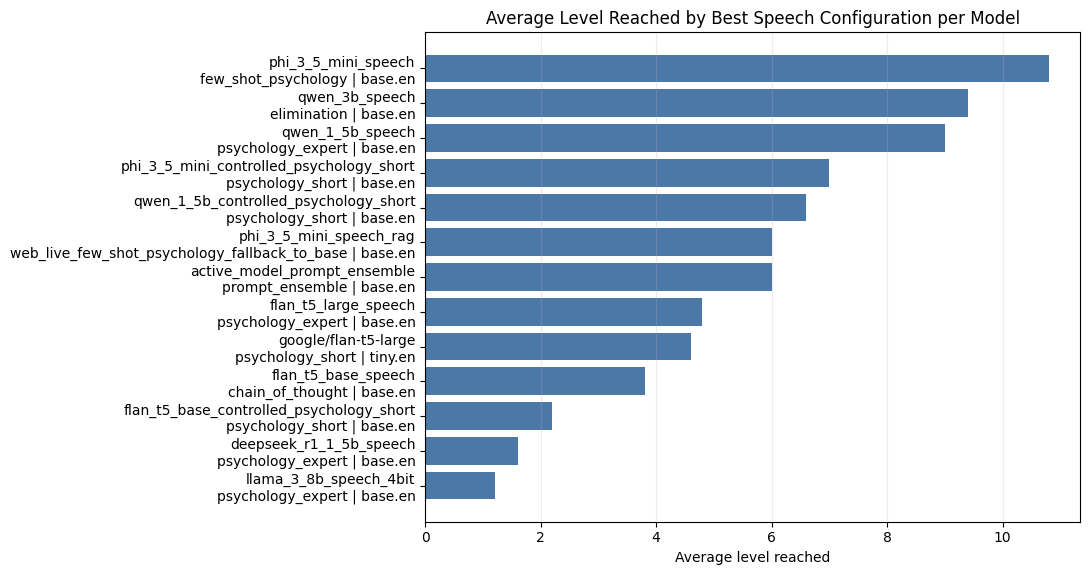

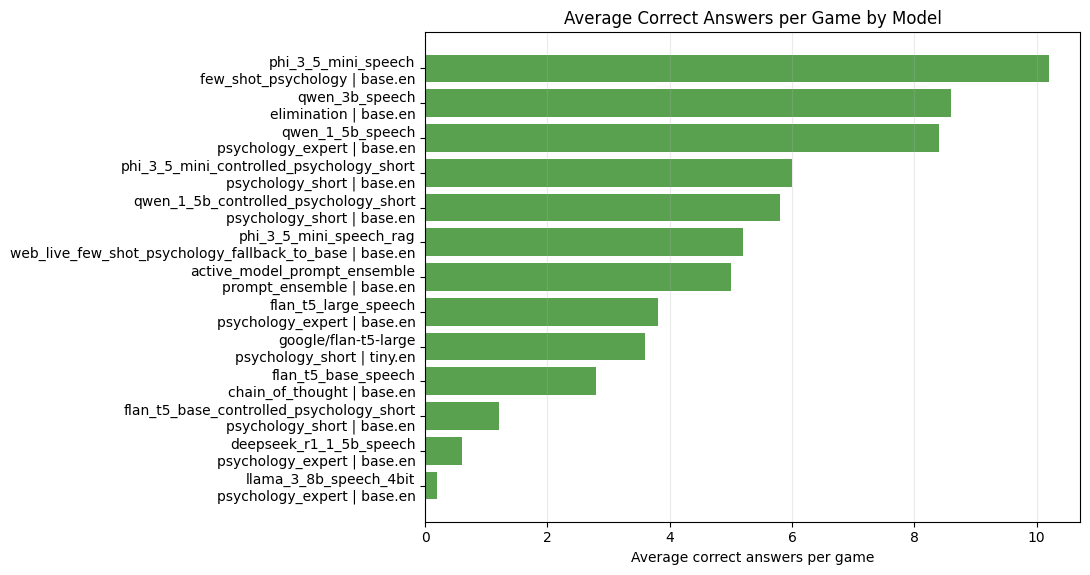

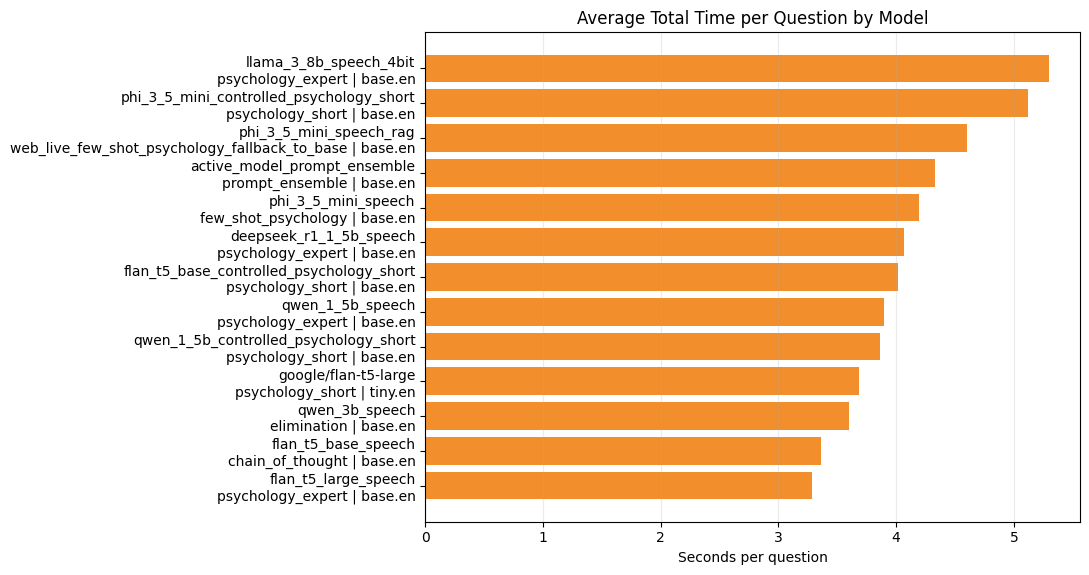

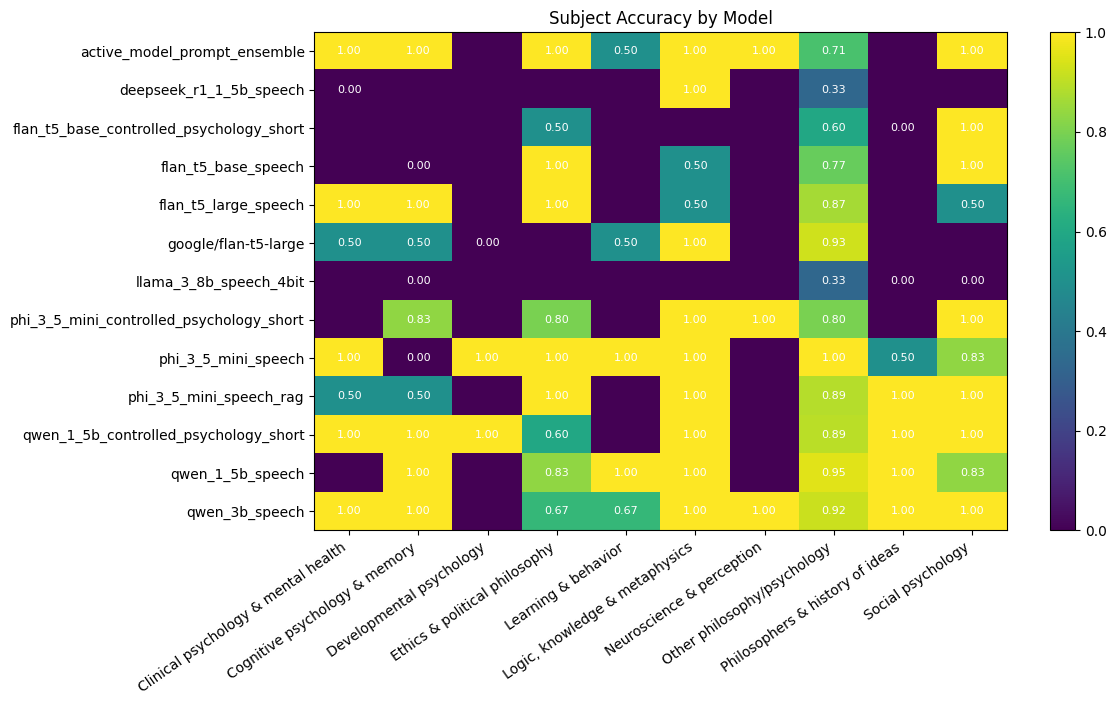

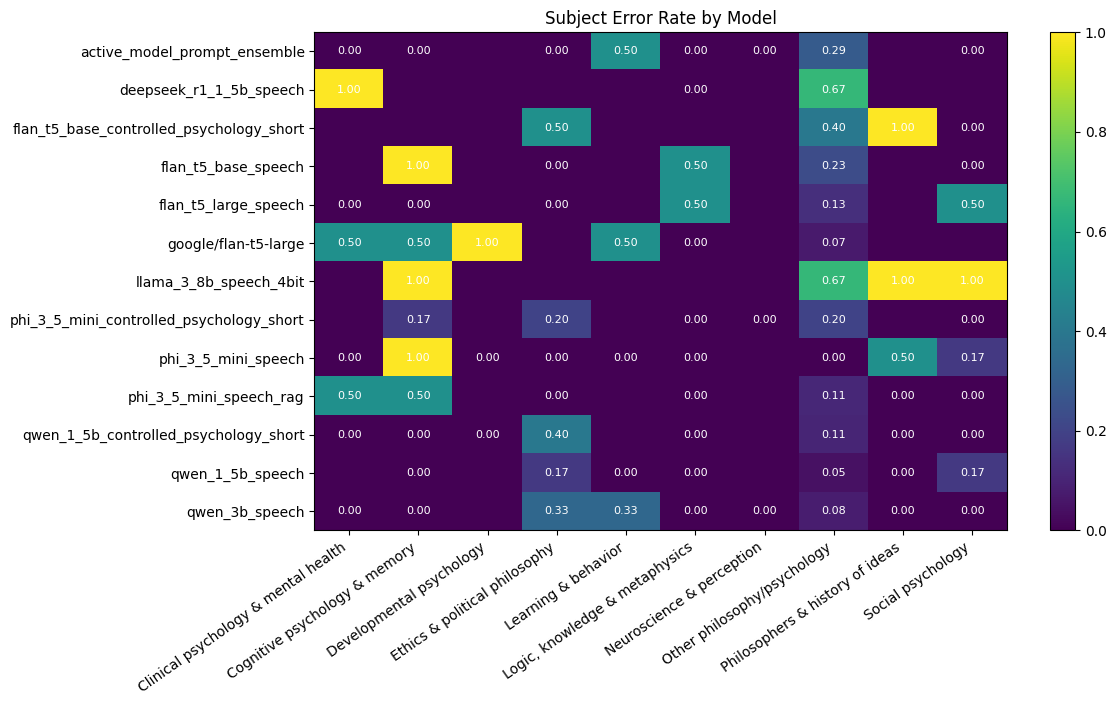

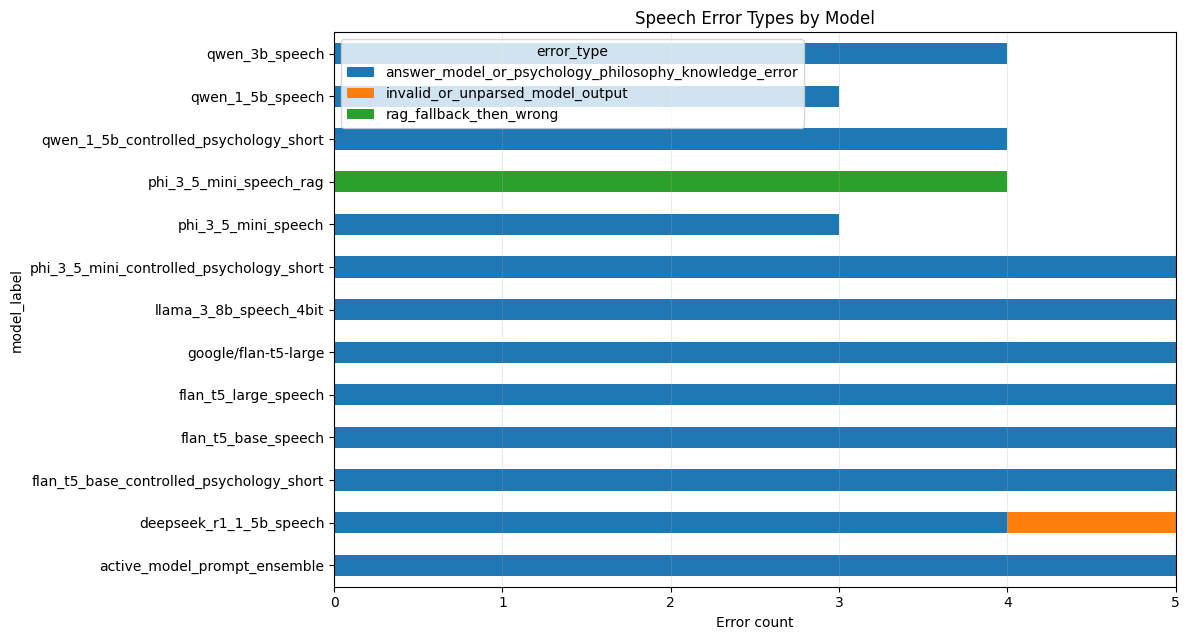

Saved clean CSV and PNG outputs in: speech_psychology_5run_comparison_outputs


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


SPEECH_COMPARISON_EXPECTED_RUNS = 5
SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS = 2
SPEECH_COMPARISON_OUTPUT_DIR = Path("speech_psychology_5run_comparison_outputs")
SPEECH_COMPARISON_OUTPUT_DIR.mkdir(exist_ok=True)

SPEECH_COMPARABLE_LOG_NAMES = [
    "df_speech_prompt_benchmark",
    "df_speech_asr_comparison",
    "df_speech_answer_model_comparison",
    "df_speech_rag",
    "df_speech_prompt_ensemble",
    "df_speech_controlled_final",
]

SPEECH_NAN_GUIDE = pd.DataFrame(
    [
        {
            "field_type": "RAG fields",
            "why_nan_appears": "Only RAG runs have retrieval scores, sources, and fallback reasons.",
            "what_to_do": "Compare RAG metrics only inside the RAG rows.",
        },
        {
            "field_type": "WER fields",
            "why_nan_appears": "WER needs a reference question and the jiwer package.",
            "what_to_do": "Use ASR log probability and manual examples when WER is unavailable.",
        },
        {
            "field_type": "Legacy rows",
            "why_nan_appears": "Older quick tests did not log every enhanced column.",
            "what_to_do": "Use the clean tables in this section for the final report.",
        },
    ]
)

display(SPEECH_NAN_GUIDE)


def collect_comparable_speech_logs(include_legacy_speech_results=False):
    logs = []

    for name in SPEECH_COMPARABLE_LOG_NAMES:
        value = globals().get(name)
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if include_legacy_speech_results:
        value = globals().get("speech_results")
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = "speech_results_legacy"
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    combined = pd.concat(logs, ignore_index=True, sort=False)

    if "mode" in combined.columns:
        mode_text = combined["mode"].fillna("speech").astype(str).str.lower()
        combined = combined[mode_text.eq("speech")].copy()

    return combined


def prepare_comparable_speech_logs(include_legacy_speech_results=False):
    raw_logs = collect_comparable_speech_logs(include_legacy_speech_results=include_legacy_speech_results)
    if raw_logs.empty:
        return pd.DataFrame()

    prepared = prepare_speech_question_level_analysis(raw_logs)
    if "source_table" not in prepared.columns:
        prepared["source_table"] = "unknown_source"

    for flag_column in ["correct", "valid_output", "used_fallback", "under_30_seconds", "near_timeout", "low_asr_confidence"]:
        if flag_column in prepared.columns:
            prepared[flag_column] = prepared[flag_column].fillna(False).astype(bool)

    for numeric_column in [
        "elapsed_seconds",
        "answer_elapsed_seconds",
        "question_asr_elapsed_seconds",
        "option_asr_elapsed_seconds",
        "question_wer",
        "rag_retrieval_score",
    ]:
        if numeric_column in prepared.columns:
            prepared[numeric_column] = pd.to_numeric(prepared[numeric_column], errors="coerce")

    prepared["comparison_config"] = (
        prepared["model_label"].astype(str)
        + " | "
        + prepared["prompt_type"].astype(str)
        + " | ASR="
        + prepared["asr_model"].astype(str)
    )
    prepared["comparison_run_key"] = (
        prepared["source_table"].astype(str)
        + "__"
        + prepared["model_label"].astype(str)
        + "__"
        + prepared["prompt_type"].astype(str)
        + "__"
        + prepared["asr_model"].astype(str)
        + "__run_"
        + prepared["run_id"].astype(str)
    )
    return prepared


def build_5run_model_comparison(prepared):
    if prepared.empty:
        return pd.DataFrame(), pd.DataFrame()

    run_level = prepared.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config", "comparison_run_key"]
    ).agg(
        level_reached=("correct", "count"),
        correct_answers=("correct", "sum"),
        final_earned_amount=("earned_amount", "max"),
        average_total_time_per_question=("elapsed_seconds", "mean"),
        max_total_time=("elapsed_seconds", "max"),
        average_answer_time=("answer_elapsed_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_option_asr_time=("option_asr_elapsed_seconds", "mean"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        valid_output_rate=("valid_output", "mean"),
        fallback_rate=("used_fallback", "mean"),
        near_timeout_rate=("near_timeout", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
        average_question_wer=("question_wer", "mean"),
    ).reset_index()

    config_summary = run_level.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config"]
    ).agg(
        runs_completed=("comparison_run_key", "nunique"),
        average_level_achieved=("level_reached", "mean"),
        best_level_achieved=("level_reached", "max"),
        average_correct_answers_in_game=("correct_answers", "mean"),
        best_correct_answers_in_game=("correct_answers", "max"),
        total_correct_answers=("correct_answers", "sum"),
        average_final_earned_amount=("final_earned_amount", "mean"),
        best_final_earned_amount=("final_earned_amount", "max"),
        average_total_time_per_question=("average_total_time_per_question", "mean"),
        max_total_time=("max_total_time", "max"),
        average_answer_time=("average_answer_time", "mean"),
        average_question_asr_time=("average_question_asr_time", "mean"),
        average_option_asr_time=("average_option_asr_time", "mean"),
        under_30_seconds_rate=("under_30_seconds_rate", "mean"),
        valid_output_rate=("valid_output_rate", "mean"),
        fallback_rate=("fallback_rate", "mean"),
        near_timeout_rate=("near_timeout_rate", "mean"),
        low_asr_confidence_count=("low_asr_confidence_count", "sum"),
        average_question_wer=("average_question_wer", "mean"),
    ).reset_index()

    config_summary["average_game_accuracy_out_of_15"] = (
        config_summary["average_correct_answers_in_game"] / MAX_GAME_QUESTIONS
    )
    config_summary["needs_more_runs"] = config_summary["runs_completed"] < SPEECH_COMPARISON_EXPECTED_RUNS
    config_summary = config_summary.sort_values(
        [
            "average_level_achieved",
            "average_correct_answers_in_game",
            "under_30_seconds_rate",
            "average_total_time_per_question",
        ],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)
    config_summary.insert(0, "rank", range(1, len(config_summary) + 1))

    return config_summary, run_level


def choose_best_config_per_model(config_summary):
    if config_summary.empty:
        return pd.DataFrame()

    return (
        config_summary.sort_values(
            [
                "model_label",
                "average_level_achieved",
                "average_correct_answers_in_game",
                "under_30_seconds_rate",
                "average_total_time_per_question",
            ],
            ascending=[True, False, False, False, True],
        )
        .groupby("model_label")
        .head(1)
        .sort_values(
            ["average_level_achieved", "average_correct_answers_in_game", "under_30_seconds_rate"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def filter_to_best_model_configs(prepared, best_config_per_model):
    if prepared.empty or best_config_per_model.empty:
        return pd.DataFrame()

    keys = best_config_per_model[["source_table", "model_label", "prompt_type", "asr_model"]].drop_duplicates()
    return prepared.merge(keys, on=["source_table", "model_label", "prompt_type", "asr_model"], how="inner")


def build_subject_and_error_tables(best_logs):
    if best_logs.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    subject_model_summary = best_logs.groupby(["model_label", "topic"]).agg(
        subject_questions=("correct", "count"),
        subject_correct_answers=("correct", "sum"),
        subject_accuracy=("correct", "mean"),
        subject_errors=("correct", lambda values: (~values.astype(bool)).sum()),
        average_total_time=("elapsed_seconds", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index()
    subject_model_summary["subject_error_rate"] = (
        subject_model_summary["subject_errors"] / subject_model_summary["subject_questions"].clip(lower=1)
    )

    best_model_by_subject = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["topic", "subject_accuracy", "subject_correct_answers", "subject_questions", "average_total_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
        .rename(columns={"model_label": "best_model_for_subject"})
    )

    error_by_model_subject_type = (
        best_logs[best_logs["correct"] == False]
        .groupby(["model_label", "topic", "error_type"])
        .size()
        .reset_index(name="error_count")
        .sort_values(["model_label", "topic", "error_count"], ascending=[True, True, False])
    )

    weak_subjects_by_model = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["model_label", "subject_error_rate", "subject_errors", "subject_questions"],
            ascending=[True, False, False, False],
        )
        .groupby("model_label")
        .head(3)
        .reset_index(drop=True)
    )

    return subject_model_summary, best_model_by_subject, error_by_model_subject_type, weak_subjects_by_model


def save_barh_plot(df, label_column, value_column, title, xlabel, filename, color="#4C78A8"):
    if df.empty or value_column not in df.columns:
        return

    plot_data = df[[label_column, value_column]].dropna().sort_values(value_column)
    if plot_data.empty:
        return

    height = max(4, 0.45 * len(plot_data))
    fig, ax = plt.subplots(figsize=(11, height))
    ax.barh(plot_data[label_column].astype(str), plot_data[value_column], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


def save_heatmap(table, title, filename, value_format="{:.2f}", vmin=0.0, vmax=1.0):
    if table.empty:
        return

    data = table.copy()
    rows = list(data.index.astype(str))
    columns = list(data.columns.astype(str))
    values = data.to_numpy(dtype=float)

    fig_width = max(8, 1.2 * len(columns))
    fig_height = max(4, 0.55 * len(rows))
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    image = ax.imshow(np.nan_to_num(values, nan=0.0), aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax)

    ax.set_title(title)
    ax.set_xticks(range(len(columns)))
    ax.set_xticklabels(columns, rotation=35, ha="right")
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows)

    for row_idx in range(values.shape[0]):
        for col_idx in range(values.shape[1]):
            value = values[row_idx, col_idx]
            if np.isfinite(value):
                ax.text(col_idx, row_idx, value_format.format(value), ha="center", va="center", color="white", fontsize=8)

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


def save_stacked_error_plot(error_by_model_subject_type, filename="speech_error_types_by_model.png"):
    if error_by_model_subject_type.empty:
        return

    error_by_model = error_by_model_subject_type.groupby(["model_label", "error_type"])["error_count"].sum().unstack(fill_value=0)
    if error_by_model.empty:
        return

    fig, ax = plt.subplots(figsize=(12, max(4, 0.5 * len(error_by_model))))
    error_by_model.plot(kind="barh", stacked=True, ax=ax)
    ax.set_title("Speech Error Types by Model")
    ax.set_xlabel("Error count")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


speech_comparable_logs = prepare_comparable_speech_logs(include_legacy_speech_results=False)

if speech_comparable_logs.empty:
    print("No comparable enhanced speech logs found yet. Run the model/RAG/comparison cells above first.")
else:
    speech_5run_model_comparison, speech_5run_run_level = build_5run_model_comparison(speech_comparable_logs)
    speech_best_config_per_model = choose_best_config_per_model(speech_5run_model_comparison)
    speech_best_model_logs = filter_to_best_model_configs(speech_comparable_logs, speech_best_config_per_model)

    (
        speech_subject_model_summary,
        speech_best_model_by_subject,
        speech_error_by_model_subject_type,
        speech_weak_subjects_by_model,
    ) = build_subject_and_error_tables(speech_best_model_logs)

    speech_5run_model_comparison.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_clean_config_summary.csv", index=False)
    speech_5run_run_level.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_clean_run_level_summary.csv", index=False)
    speech_best_config_per_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_best_config_per_model.csv", index=False)
    speech_subject_model_summary.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_topic_summary.csv", index=False)
    speech_best_model_by_subject.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_best_model_by_topic.csv", index=False)
    speech_error_by_model_subject_type.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_error_summary.csv", index=False)
    speech_weak_subjects_by_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_psychology_weak_topics_by_model.csv", index=False)

    print("Clean 5-run model/configuration comparison")
    display(speech_5run_model_comparison)

    print("Best observed configuration per model")
    display(speech_best_config_per_model)

    print("Best model by subject")
    display(speech_best_model_by_subject)

    print("Weakest subjects for each model")
    display(speech_weak_subjects_by_model)

    print("Error analysis by model, subject, and error type")
    display(speech_error_by_model_subject_type)

    speech_best_config_per_model["model_config_label"] = (
        speech_best_config_per_model["model_label"].astype(str)
        + "\n"
        + speech_best_config_per_model["prompt_type"].astype(str)
        + " | "
        + speech_best_config_per_model["asr_model"].astype(str)
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_level_achieved",
        "Average Level Reached by Best Speech Configuration per Model",
        "Average level reached",
        "speech_psychology_average_level_by_model.png",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_correct_answers_in_game",
        "Average Correct Answers per Game by Model",
        "Average correct answers per game",
        "speech_psychology_average_correct_answers_by_model.png",
        color="#59A14F",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_total_time_per_question",
        "Average Total Time per Question by Model",
        "Seconds per question",
        "speech_psychology_average_time_by_model.png",
        color="#F28E2B",
    )

    if not speech_subject_model_summary.empty:
        subject_accuracy_heatmap = speech_subject_model_summary.pivot_table(
            index="model_label",
            columns="topic",
            values="subject_accuracy",
            aggfunc="mean",
        )
        save_heatmap(
            subject_accuracy_heatmap,
            "Subject Accuracy by Model",
            "speech_psychology_topic_accuracy_heatmap.png",
        )

        subject_error_heatmap = speech_subject_model_summary.pivot_table(
            index="model_label",
            columns="topic",
            values="subject_error_rate",
            aggfunc="mean",
        )
        save_heatmap(
            subject_error_heatmap,
            "Subject Error Rate by Model",
            "speech_psychology_topic_error_rate_heatmap.png",
        )

    save_stacked_error_plot(speech_error_by_model_subject_type)

    print("Saved clean CSV and PNG outputs in:", SPEECH_COMPARISON_OUTPUT_DIR)


## Final report: Speech Philosophy & Psychology experiments

### Aim of the speech Philosophy & Psychology section

In this section I tested the Philosophy & Psychology quiz in a full speech pipeline. The system first receives the question and options as audio, then the audio is transcribed using Whisper, and then the transcribed text is sent to a local answer model. Finally, the model answer is cleaned into one of the four choices: A, B, C, or D.

So the result is not only testing the language model. It is testing the whole pipeline together: ASR transcription, prompt design, answer model reasoning, answer parsing, and timing.

### Main setup

The notebook tested different parts of the speech system:

- Whisper ASR models such as `tiny.en`, `base.en`, and `small.en`;
- different prompt styles, including baseline, psychology-short, psychology-expert, elimination, few-shot psychology, and chain-of-thought;
- different local answer models, including FLAN-T5, Qwen, Phi-3.5-mini, DeepSeek, and Llama where possible;
- a prompt ensemble;
- and a RAG extension using static psychology/philosophy retrieval and optional live web retrieval.

For the main comparison I used the clean 5-run tables, because these are more reliable than the early quick test rows.

---

## Main result

The best overall speech configuration was:

**`phi_3_5_mini_speech` + `few_shot_psychology` + Whisper `base.en`**

This setup reached an average of **10.80 questions**, with a best run of **15 questions**. It also had an average of **10.20 correct answers in the game**, an average run accuracy of **0.908**, and a game accuracy out of 15 of **0.680**.

This was the strongest result in the notebook because it combined high survival with high accuracy. It also stayed inside the time limit, with an under-30-second rate of **1.00** and a valid-output rate of **1.00**. There were no near-timeout problems and no low-ASR-confidence cases reported for this row.

The second-best setup was `qwen_3b_speech` with the `elimination` prompt. It reached **9.40 questions on average**, with a best run of **15 questions** and an average of **8.60 correct answers**. This shows that Qwen 3B was also strong, especially when the prompt asked it to eliminate wrong options.

The third-best setup was `qwen_1_5b_speech` with `psychology_expert`. It reached **9.00 questions on average**, with a best run of **15 questions** and **8.40 correct answers** on average.

Overall, Phi-3.5-mini with few-shot prompting was the best final choice.

---

## Prompting results

Prompting made a big difference in the speech setting.

For Phi-3.5-mini, the best prompt was clearly `few_shot_psychology`. It performed much better than the other Phi prompt variants. For example, Phi with `few_shot_psychology` reached **10.80 questions on average**, while Phi with `psychology_expert` reached **7.40**, `baseline` reached **6.80**, `elimination` reached **6.80**, `psychology_short` reached **6.60**, and `chain_of_thought` reached **6.20**.

This means the few-shot examples were useful for Phi-3.5-mini. They probably helped the model follow the multiple-choice format and choose an answer more consistently.

For Qwen 3B, the best prompt was not few-shot. The strongest Qwen 3B result used the `elimination` prompt, reaching **9.40 questions on average**. This suggests that Qwen 3B benefited from being asked to compare and remove wrong options.

Chain-of-thought was not the best option in this notebook. It can make the prompt longer and slower, and it did not beat the best few-shot or elimination settings.

---

## ASR result

The final best system used Whisper `base.en`. This was the ASR model used in the best overall configuration: `phi_3_5_mini_speech` with `few_shot_psychology`.

In the early ASR comparison, the ASR models gave different results depending on the answer model and prompt. `tiny.en` looked strong in one FLAN-T5 psychology-short comparison, but for the final model comparison I kept `base.en` because it was the stable ASR setting used across the main model tests.

The important point is that ASR timing was not the main bottleneck in the final results. The best systems all stayed under the 30-second limit. For the best Phi few-shot system, the average ASR time was around **0.71 seconds**, and the whole question-level pipeline stayed fast enough.

The errors were more related to model reasoning and specialist term recognition than to timeout.

---

## Answer-model comparison

The answer-model comparison shows that Phi-3.5-mini was the strongest model in this speech task.

The top three systems were:

1. `phi_3_5_mini_speech` + `few_shot_psychology`: **10.80 average questions reached**
2. `qwen_3b_speech` + `elimination`: **9.40 average questions reached**
3. `qwen_1_5b_speech` + `psychology_expert`: **9.00 average questions reached**

Qwen 3B and Qwen 1.5B were strong, but Phi-3.5-mini was better overall because it reached more questions and had higher average run accuracy.

FLAN-T5-large was useful in some prompt settings, but it was not as strong as Phi or Qwen in the clean final ranking. Smaller or less stable models such as DeepSeek-R1-Distill-Qwen-1.5B and Llama-3-8B-4bit performed much worse in this notebook. DeepSeek also had more invalid or unparsed outputs, which made it less reliable for this task.

So the final answer model choice is Phi-3.5-mini.

---

## RAG result

After fixing the RAG section, RAG was tested with the correct best setup:

**Phi-3.5-mini + `few_shot_psychology` + Whisper `base.en`**

This is important because the earlier RAG version used a generic active-model label, but the fixed version clearly loads `microsoft/Phi-3.5-mini-instruct`.

For the main reproducible RAG result, I use `psych_static_few_shot_psychology`. This reached **5.20 questions on average**, with a best run of **12 questions** and an average run accuracy of **0.888**. It used retrieval properly, with `rag_used_rate = 1.00` and an average retrieval score of about **0.360**.

This was much better than its matching fallback-to-base row, which reached only **1.20 questions on average**. So within the RAG experiment, static retrieval helped.

However, RAG did not beat the best non-RAG system. The best non-RAG Phi few-shot system reached **10.80 questions on average**, while the static RAG version reached **5.20**. Because of this, I do not use RAG as the final best system. I report it as an exploratory extension that can help when the retrieved context is good, but it still depends a lot on retrieval coverage.

The live web setting should not be used as the main result. The output showed live web search failures from rate limiting, and the best web-live row had `rag_used_rate = 0.00`, meaning it was mostly fallback-to-base rather than true RAG.

---

## Prompt ensemble result

The prompt ensemble was also tested. It reached **6.00 questions on average**, with a best run of **14 questions** and an average run accuracy of **0.740**.

This is a decent result, but it did not beat the best single-model setup. The best Phi few-shot setup was still much stronger, with **10.80 questions on average**.

So the prompt ensemble is useful as an additional experiment, but I would not choose it as the final system.

---

## Topic and error analysis

The topic analysis suggests that the strongest models handled many psychology and philosophy areas well, especially general philosophy/psychology, logic, cognitive psychology, social psychology, and ethics. Phi-3.5-mini was especially strong in the larger "Other philosophy/psychology" group.

The weaker areas were usually more specific topics, especially philosopher-history questions or questions with unusual names and terms. For example, the error table showed that the best Phi model still had errors in `Philosophers & history of ideas`, `Social psychology`, and `Cognitive psychology & memory`.

The most common error type was not timeout. The main error type was answer-model or psychology/philosophy knowledge error. This means the model usually produced a valid A/B/C/D answer, but the chosen answer was conceptually wrong.

For RAG, the main error type was `rag_fallback_then_wrong`. This means retrieval was sometimes too weak, the system fell back to the base model, and then the base model still answered wrongly.

Invalid output was not a major problem for the best models. The best Phi, Qwen, and RAG rows had valid-output rates of **1.00**. Timing was also not a major problem because the under-30-second rate was **1.00** for the main systems.

---

## Final conclusion

The best final speech system for the Philosophy & Psychology task is:

**Phi-3.5-mini + few-shot psychology prompt + Whisper `base.en`**

I choose this because it had the best average survival, the best accuracy, valid outputs, and no timing problem. It reached **10.80 questions on average** and completed a full **15-question** run at least once.

RAG was useful as an extension, but it was not the final best system. The fixed RAG experiment showed that static retrieval can improve over fallback-to-base, but it still performed worse than the best non-RAG Phi few-shot setup. Therefore, my final system is the non-RAG Phi-3.5-mini few-shot speech model, and RAG is reported as an exploratory improvement that could become stronger if the static corpus is expanded.
